In [1]:
import glob
from joblib import Parallel, delayed
#from catalog_plotter import plot_var, get_array
import numpy as np
import matplotlib.pyplot as plt
import cartopy as cp
import cartopy.crs as ccrs
import plotter_config as pc
import sim_name_remap as map
import netCDF4 as nc4
import os
import datetime as dt
from scipy.interpolate import interp1d
import pickle as pkl
import matplotlib.tri as tri
import utils
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import ListedColormap, LinearSegmentedColormap

In [2]:

def get_var_array(FILE, var_strs, t, ilev=False):

    ncfile = nc4.Dataset(FILE)
    
    if len(var_strs) > 1: 
        var_arr = []
        for sub_var in var_strs:  # Loop over all the sub variables if there are more than
            var_arr.append(ncfile.variables[sub_var][:])
        var_arr = np.nansum(np.asarray(var_arr), axis=0)  # Sum all the variables together
    else: 
        var_arr = ncfile.variables[var_strs[0]][:]

    # We assume that all these grid are unstructured.  If you are trying to plot output from a structured grid, you're going to have a bad time with this code
    if   len(np.shape(var_arr)) == 4: var_arr = np.squeeze(var_arr[t,:,:,:])
    elif len(np.shape(var_arr)) == 3: var_arr = np.squeeze(var_arr[t,:,:])
    
    lon = ncfile.variables['lon'][:]
    lat = ncfile.variables['lat'][:]

    if ilev == False: 
        hya = ncfile.variables['hyam'][:]    
        hyb = ncfile.variables['hybm'][:]
    if ilev == True: 
        hya = ncfile.variables['hyai'][:]    
        hyb = ncfile.variables['hybi'][:]        
    
    return var_arr, lon, lat, hya, hyb

# This subroutine will interpolate an unstructured variable field (dimensions of lev x pt) to a specific pressure level 
# with help from the model pressure field (dimension of lev x pt, units of Pa)

def interp_to_prslev(var_arr, PS_arr, lon, lat, hyam, hybm, plot_lev, var_name):

    #print('Interpolating ' + var_name + ' to the ' + str(plot_lev) + 'hPa surface at ' + valid_datestr)
    
    var_plev = np.zeros((len(lat), len(lon)))-999
    
    for ln in range(len(lon)):
        for lt in range(len(lat)):

            curr_PS = PS_arr[lt,ln]
            curr_plev = (hyam*1.0e5 + hybm*curr_PS)/100.  

            plev_f = interp1d(curr_plev, np.squeeze(var_arr[:,lt,ln]), bounds_error=False, fill_value=-999)

            var_plev[lt,ln] = plev_f(plot_lev)
    
    return var_plev

# This subroutine will be used to calculate a variable for a profile
def plot_prof(ax, FILE, lon, lat, prof_lon, prof_lat, plot_var, t, ilev=False, xrng=[-999]):

    var_strs = pc.var_info[plot_var]['vars']
    var_arr, lon, lat, hya, hyb = get_var_array(FILE, var_strs, t, ilev=ilev)
    PS_arr,  lon, lat, hya, hyb = get_var_array(FILE, ['PS'], t, ilev=ilev)

    lon_ind = np.argmin(np.abs(lon - prof_lon))
    lat_ind = np.argmin(np.abs(lat - prof_lat))

    prof_PS = PS_arr[lat_ind,lon_ind]
    prof_lev = (hya*1.0e5 + hyb*prof_PS)/100. 

    var_prof = var_arr[:,lat_ind,lon_ind]*pc.var_info[plot_var]['mod']

    ax.plot(var_prof, prof_lev)
    ax.set_ylim(1000,50)
    ax.set_yscale('log')
    #ax.set_ylabel('Pressure (hPa)')
    if xrng[0] > -900: ax.set_xlim(xrng)
    ax.set_xlabel(plot_var + '(' + pc.var_info[plot_var]['unit'] + ')')


In [3]:

# What are we plotting?  Only one simulation and variable allowed at this point
sim = '2022_ERA5_ZM_30m'  # Simulation to plot (much match a name in sim_name_remap.py)
plot_var = 'ZMMU'  # The species we should plot (defined in plotter_config.py)     ,'SO2','SO4'
plot_lev = 200.
prof_lon = 116.
prof_lat = 39.
PLOTDIR = '/glade/u/home/wsmith/ASM_Plotter/plots/'


In [4]:

if plot_var == 'ZMMU': 
    cbar_lev = [0,2,5,10,20,40,60,80,100,120]  # For ZMMU
    cbar_rgb = plt.get_cmap('Reds')
    
norm = BoundaryNorm(cbar_lev, ncolors = cbar_rgb.N, clip = False)


/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM.cam.h1.2022-08-18-01800.nc
File  136
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM.cam.h1.2022-08-18-12600.nc
File  137
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM.cam.h1.2022-08-18-23400.nc
File  138
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_202

/glade/derecho/scratch/wsmith/tmp/ipykernel_83086/2575913671.py:27: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(10,7))


/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM.cam.h1.2022-08-18-45000.nc
File  140
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM.cam.h1.2022-08-18-55800.nc
File  141
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022Aug_E5_ZM.cam.h1.2022-08-18-66600.nc
File  142
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_202

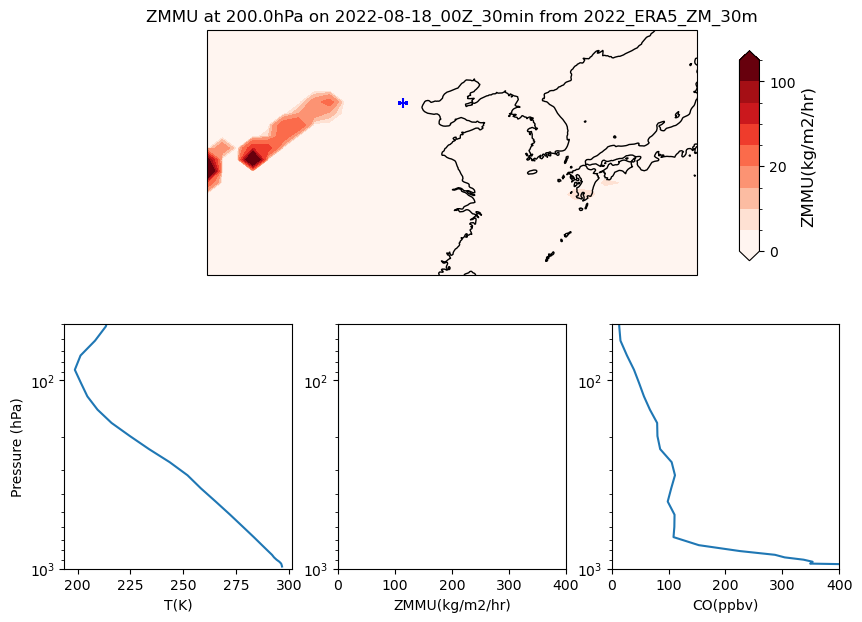

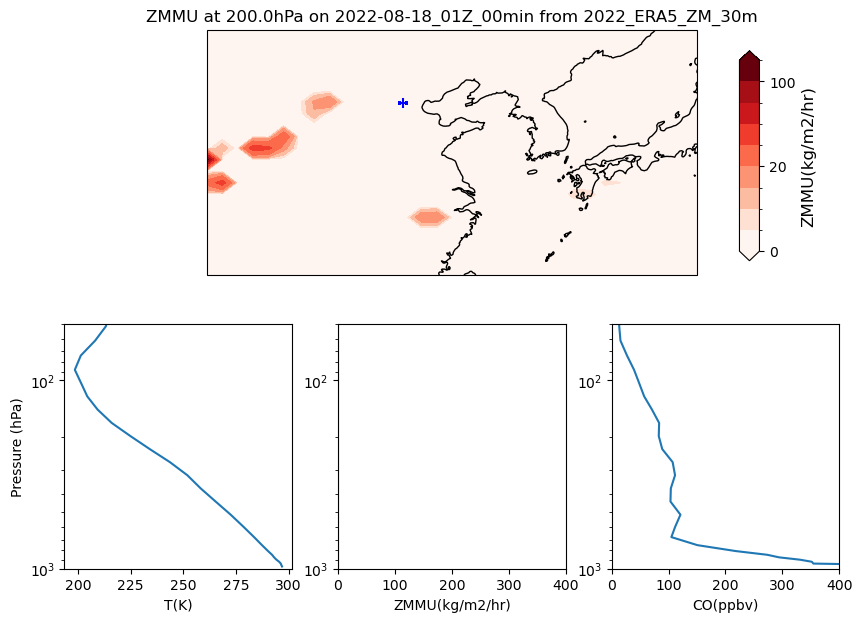

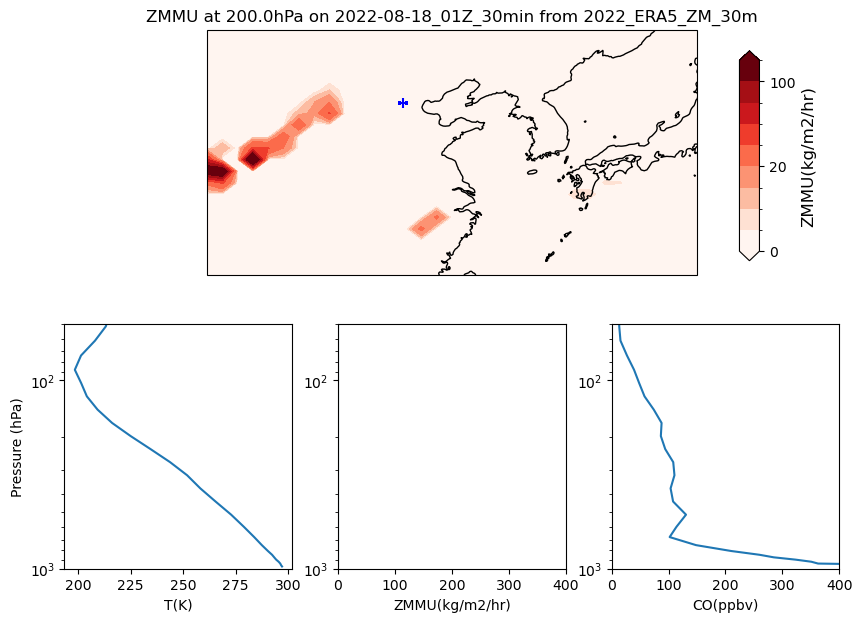

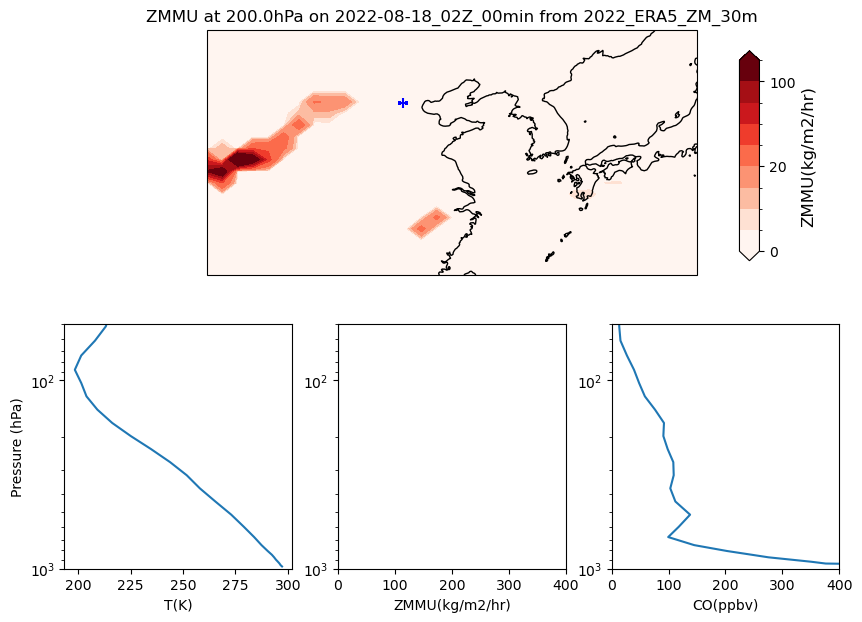

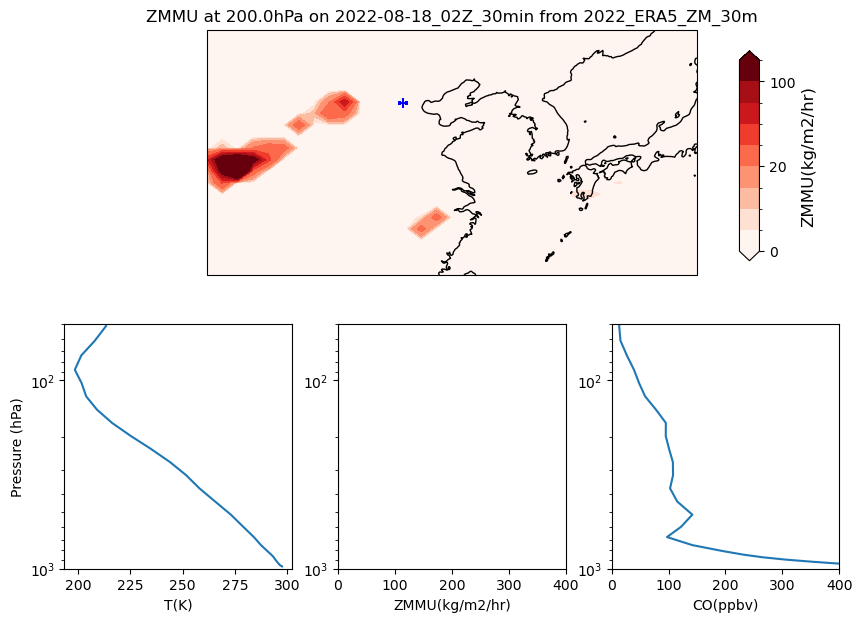

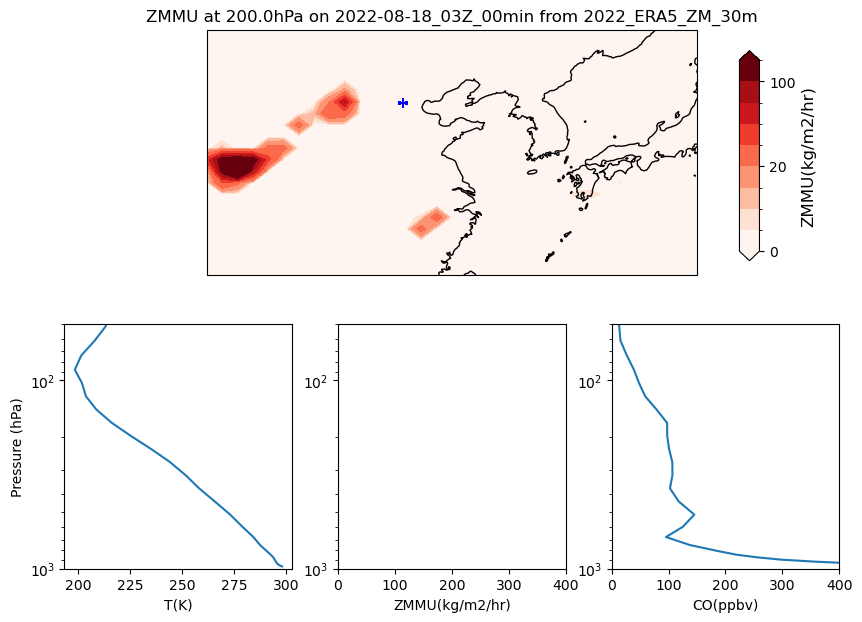

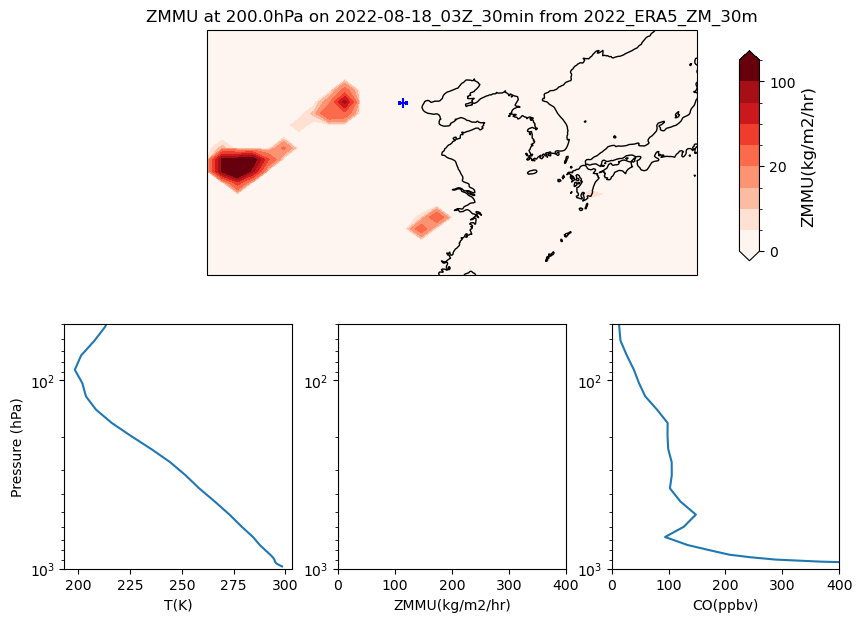

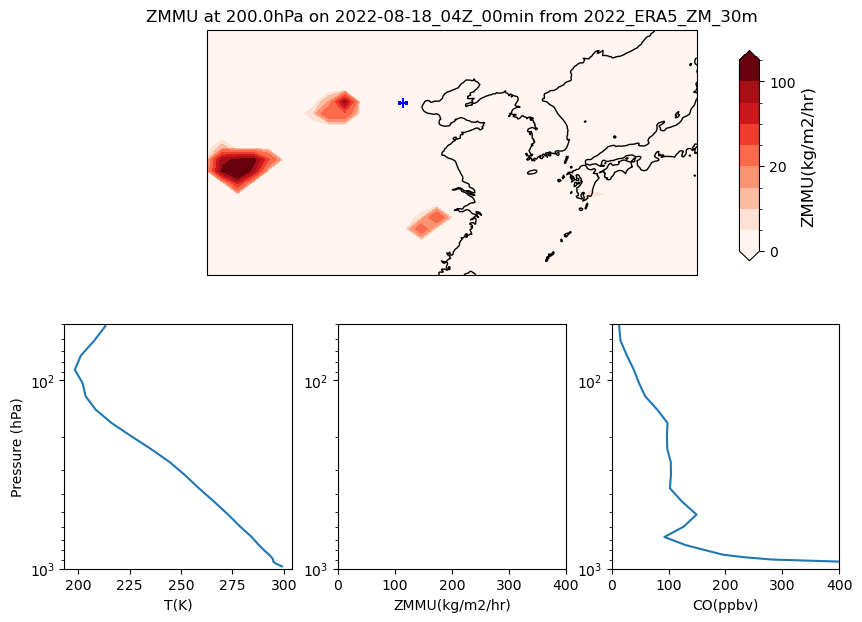

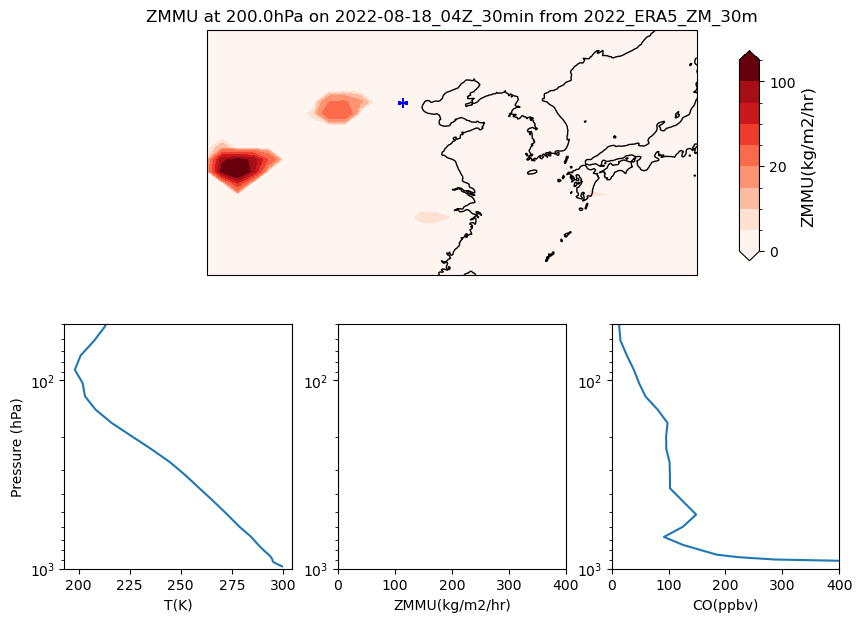

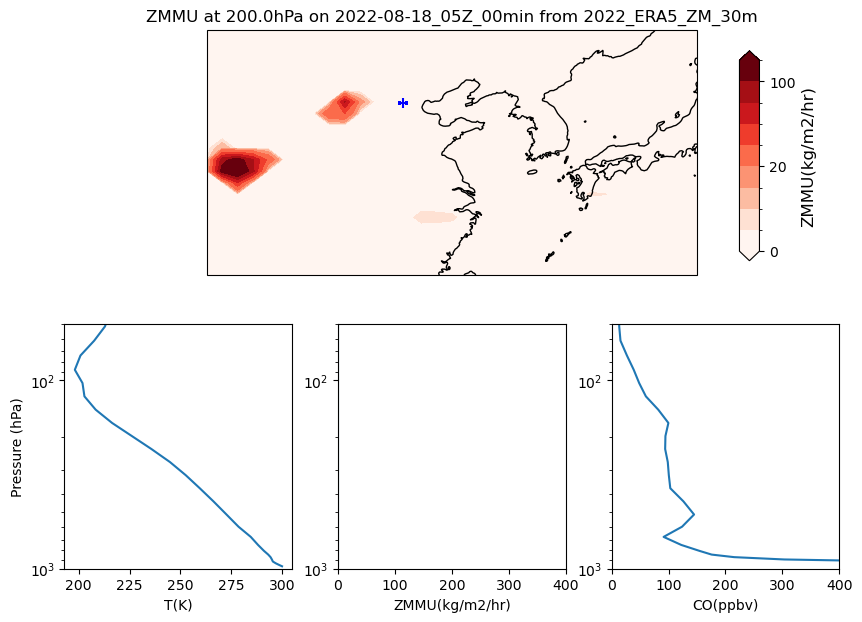

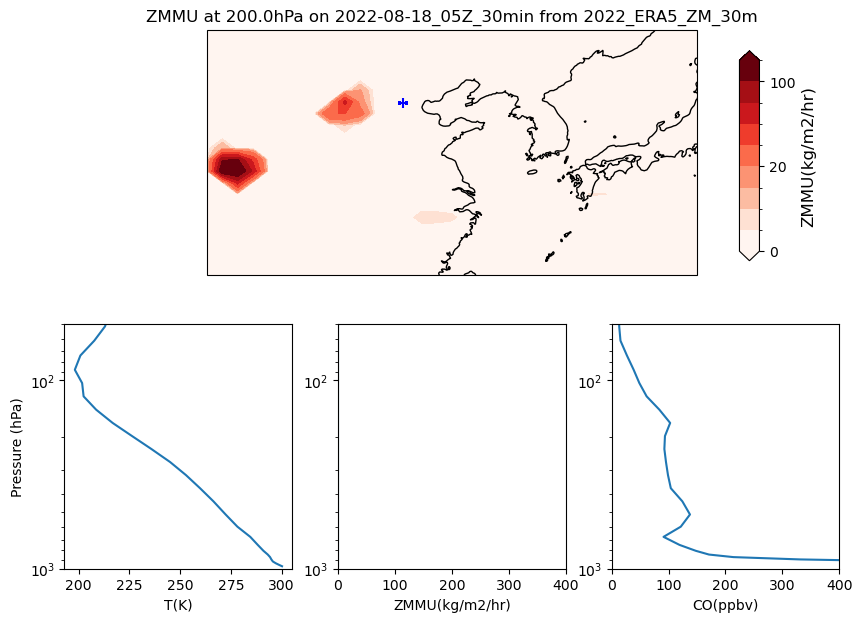

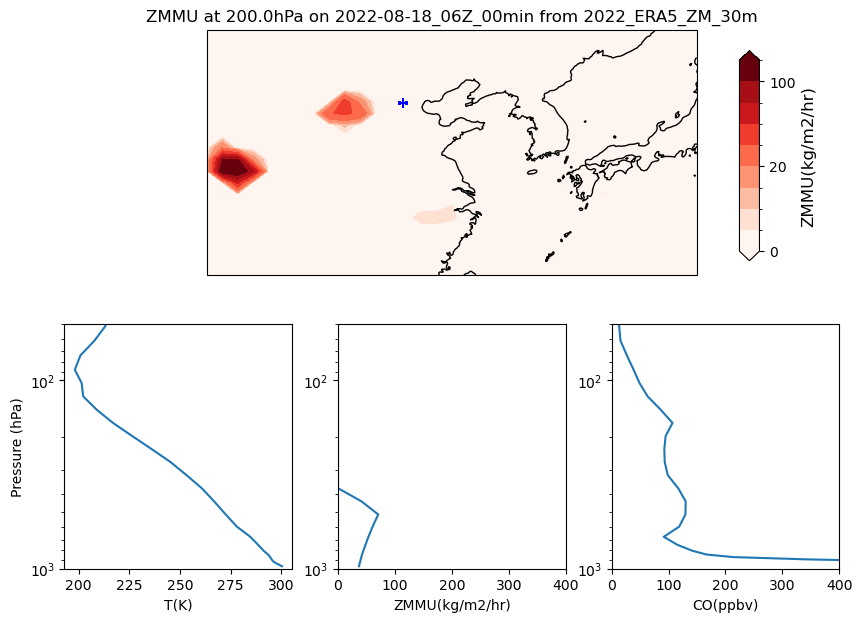

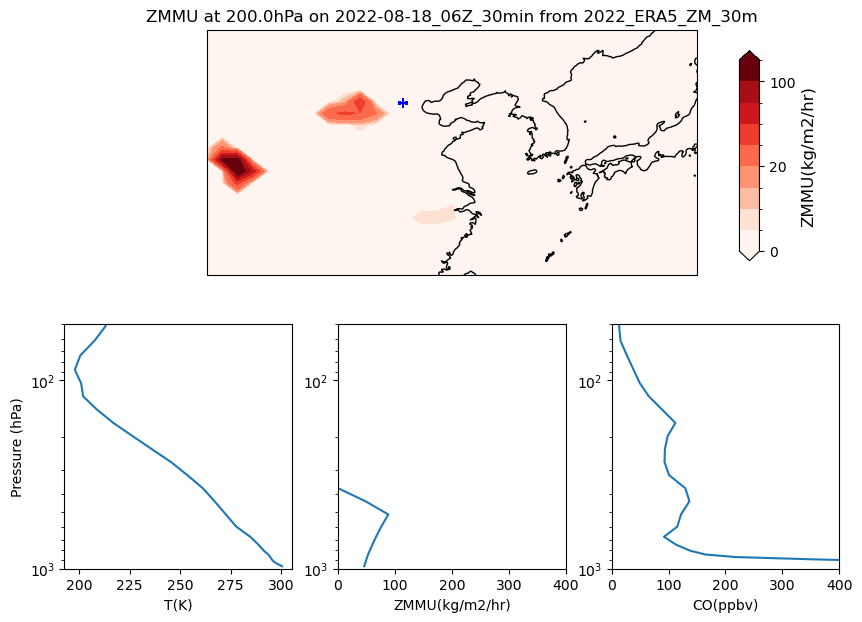

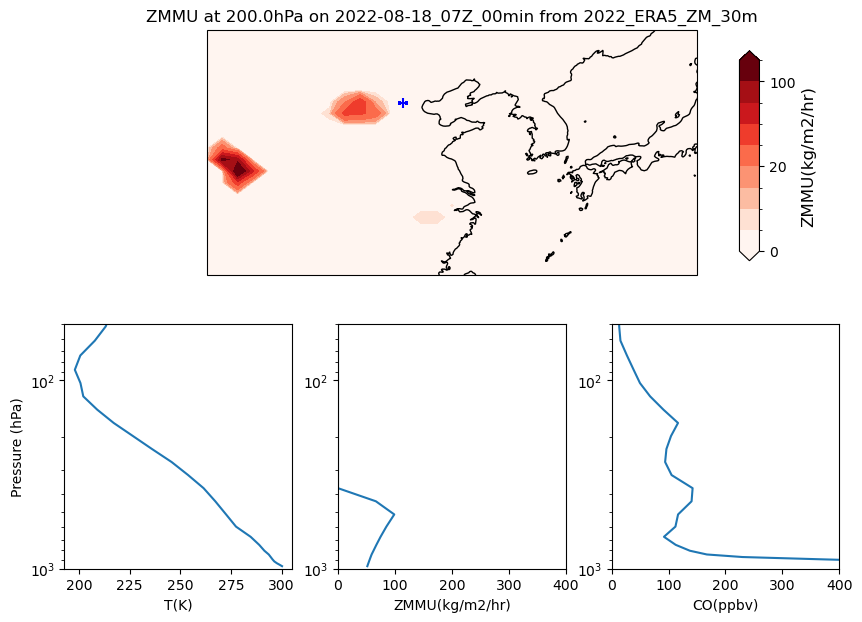

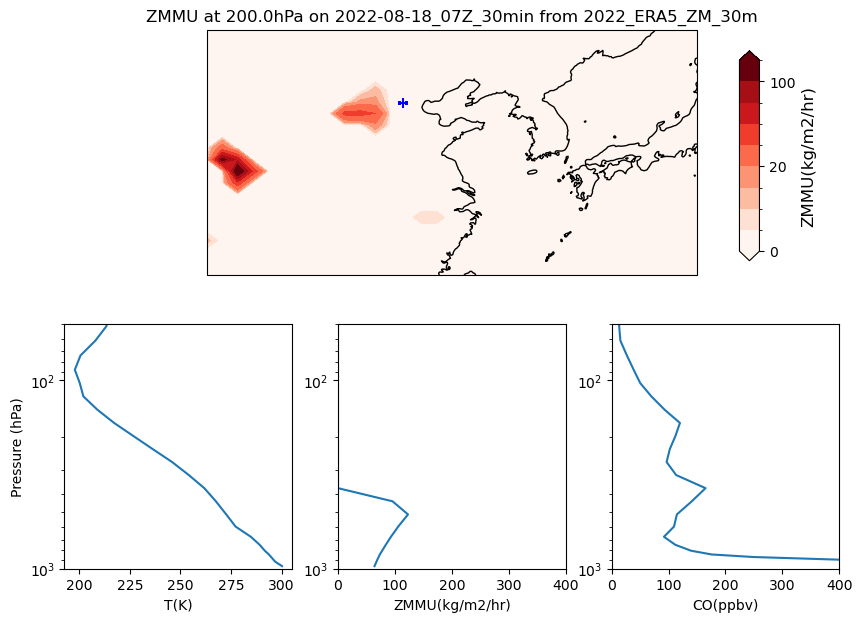

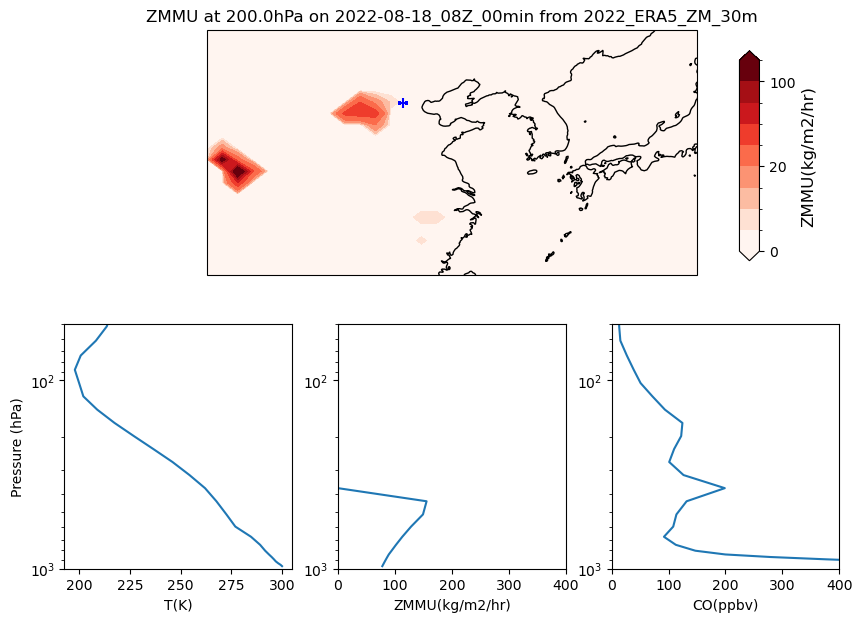

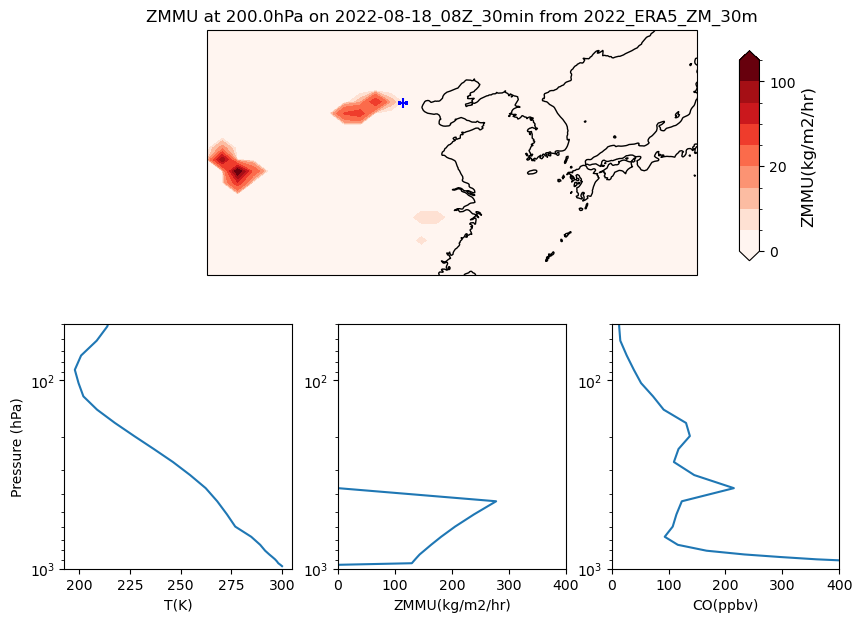

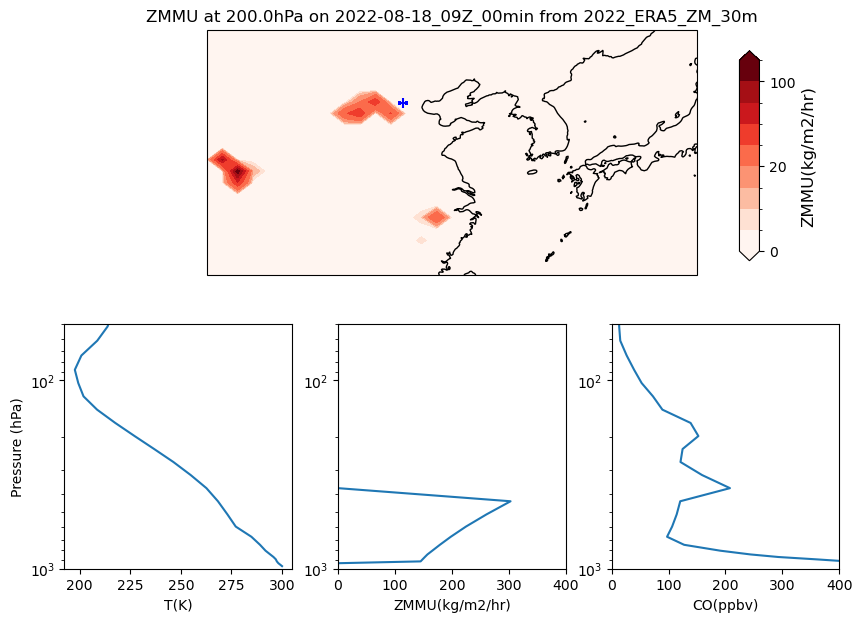

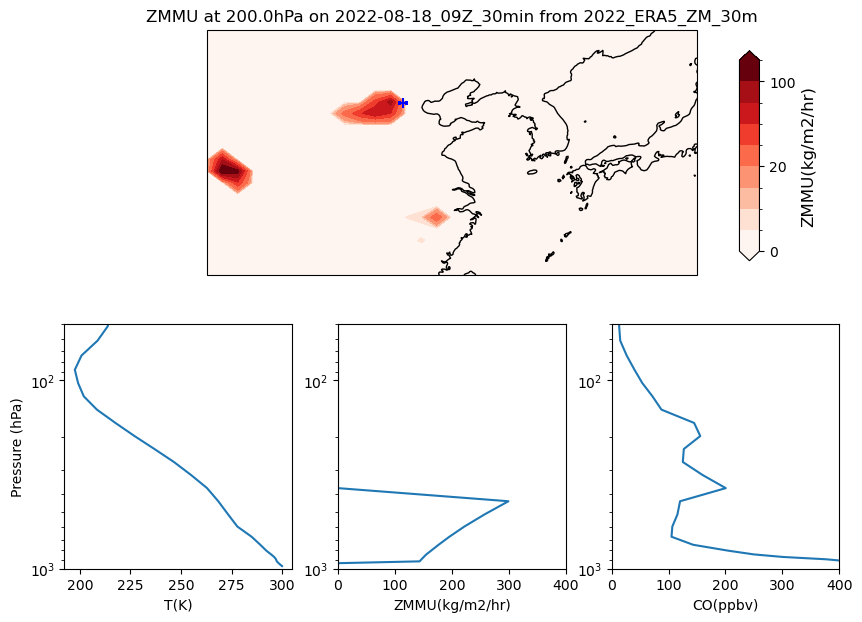

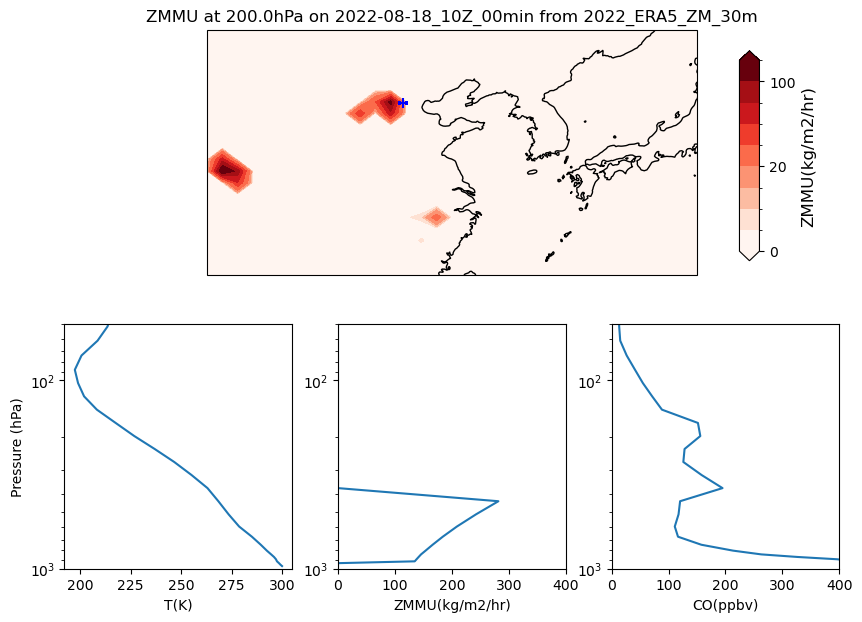

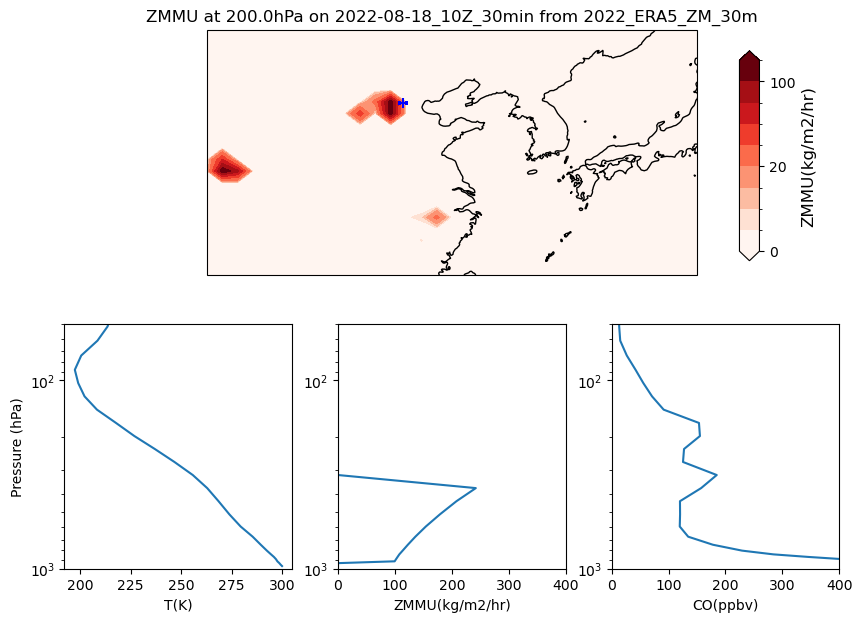

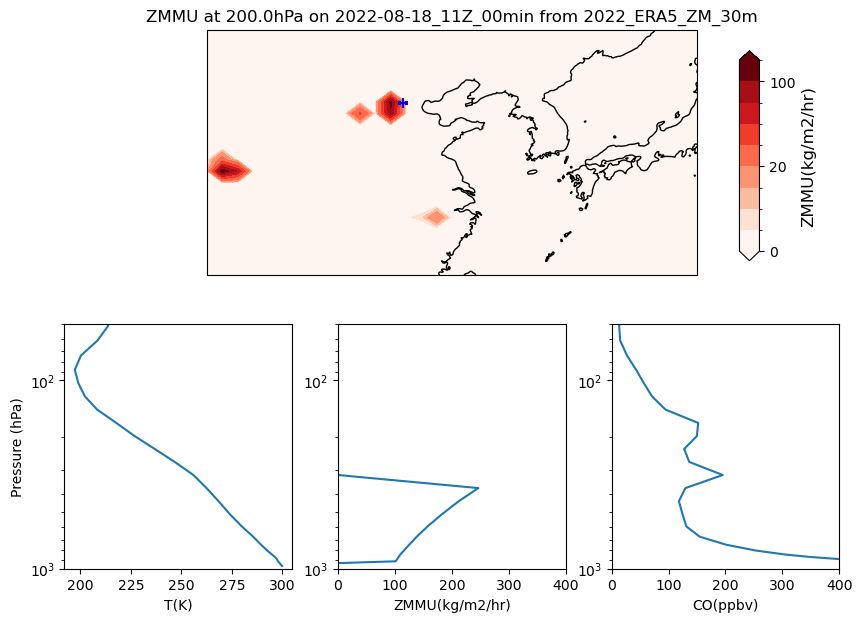

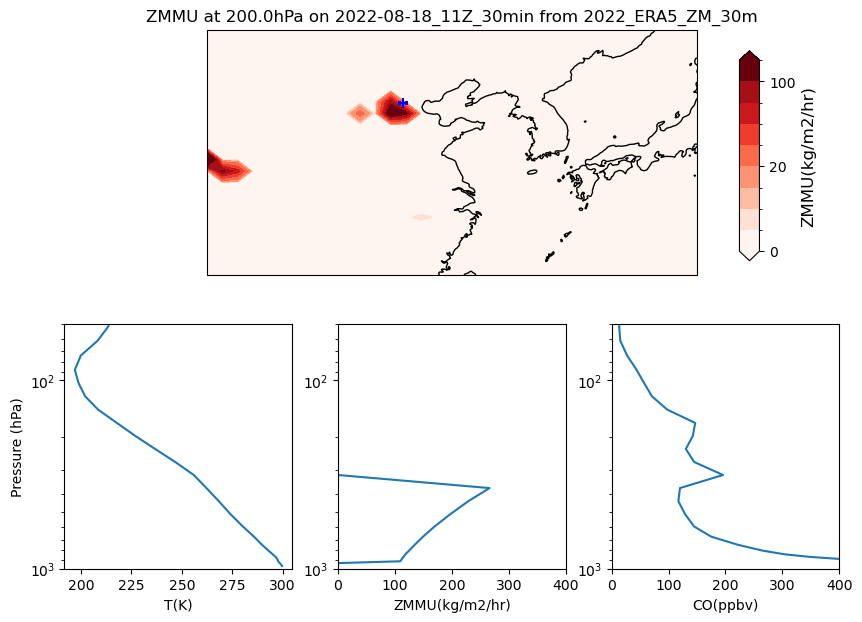

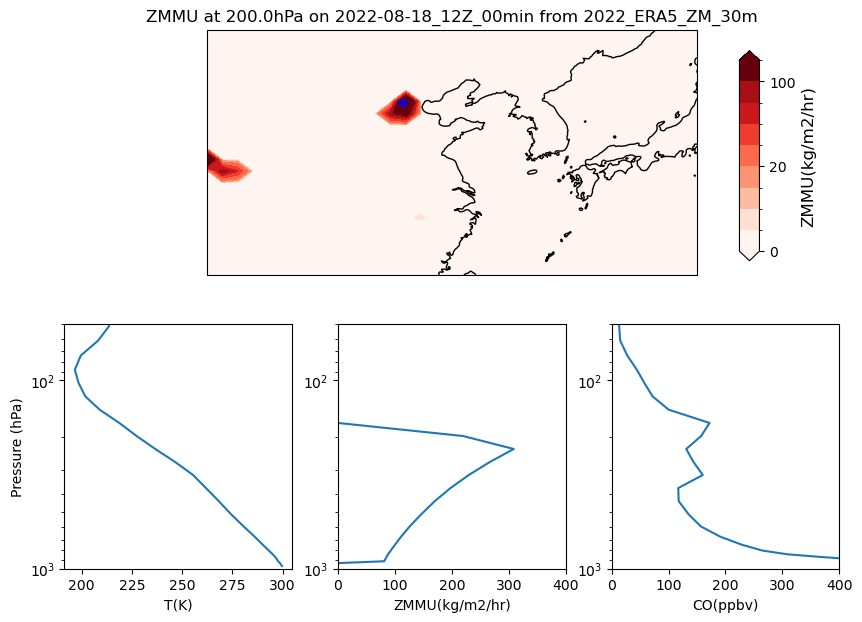

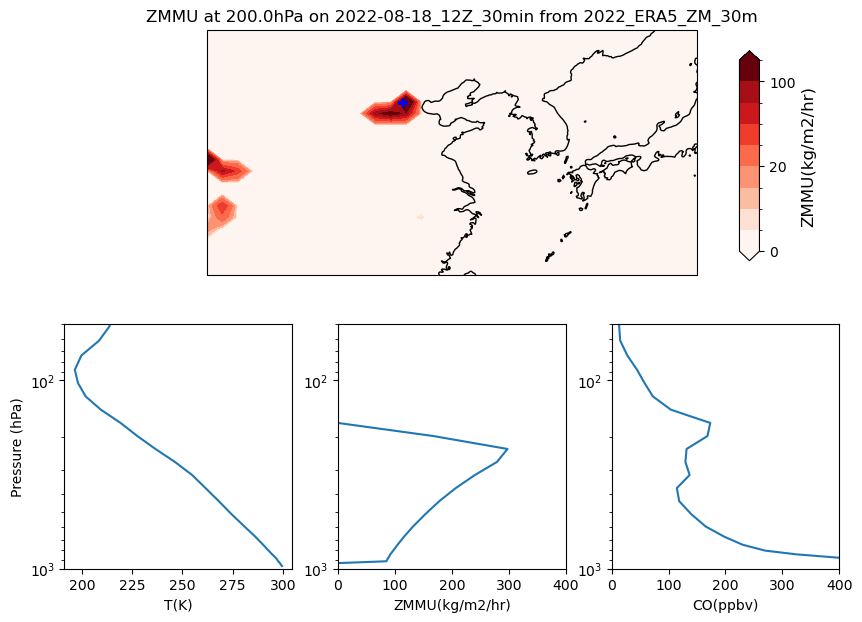

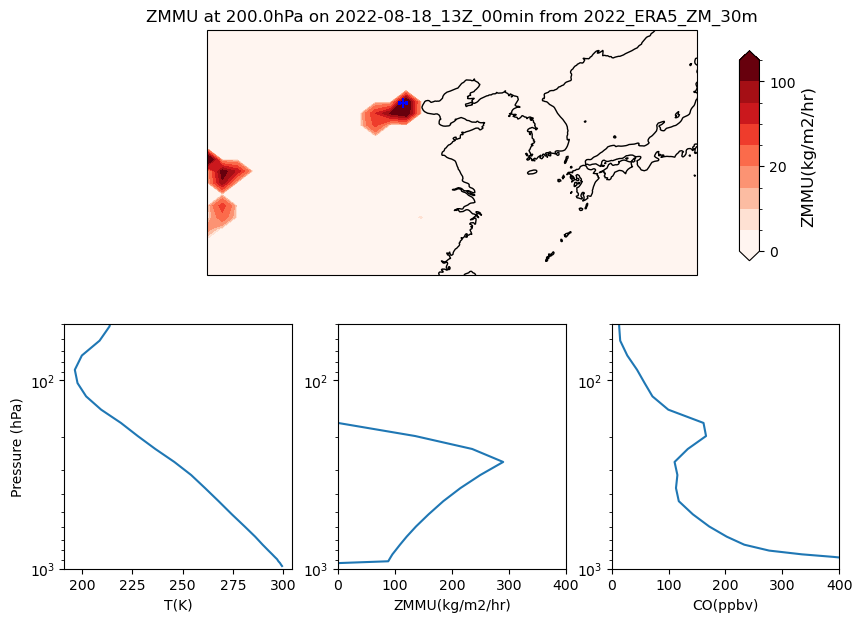

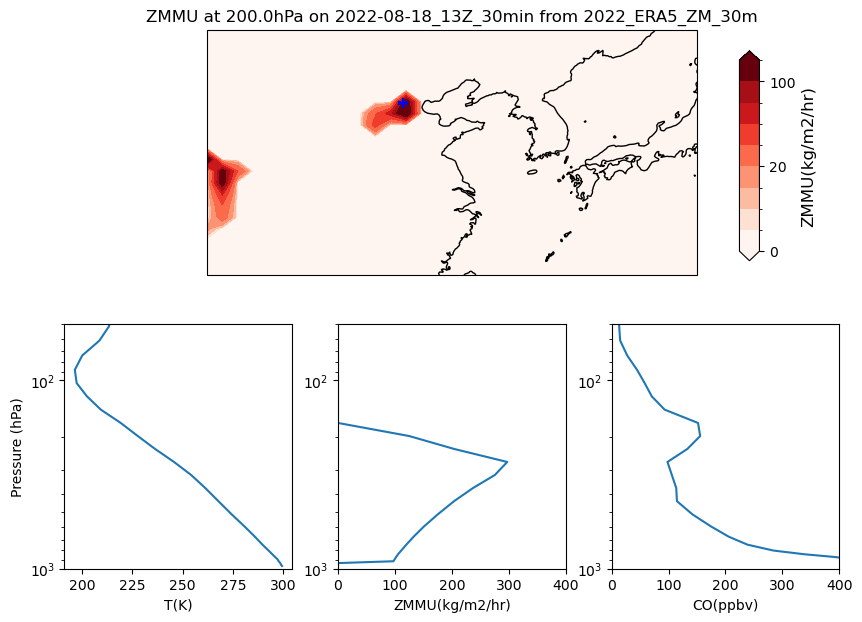

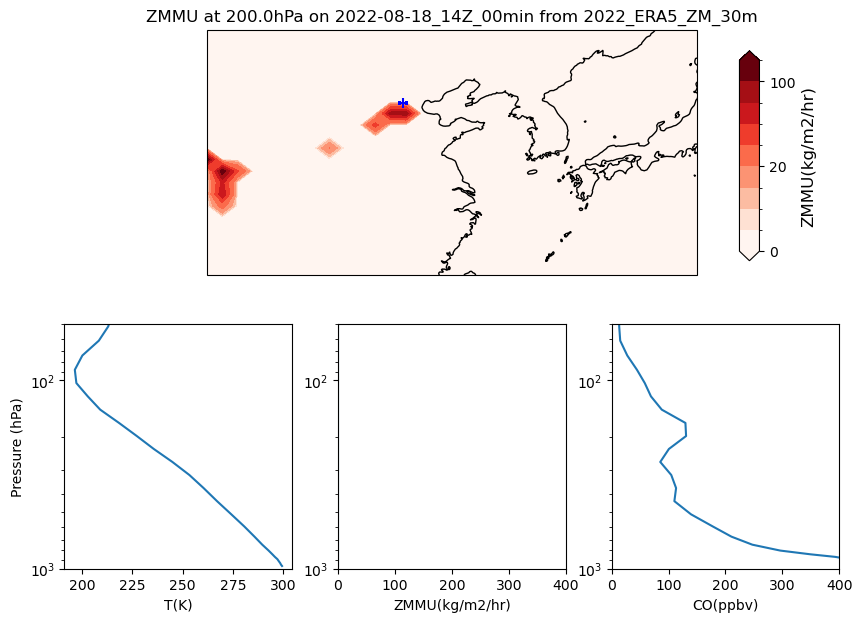

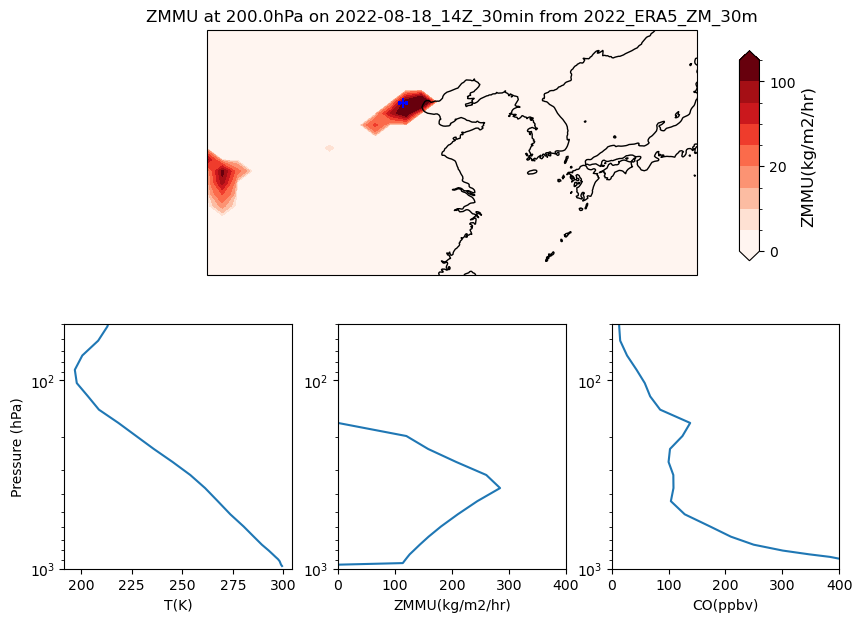

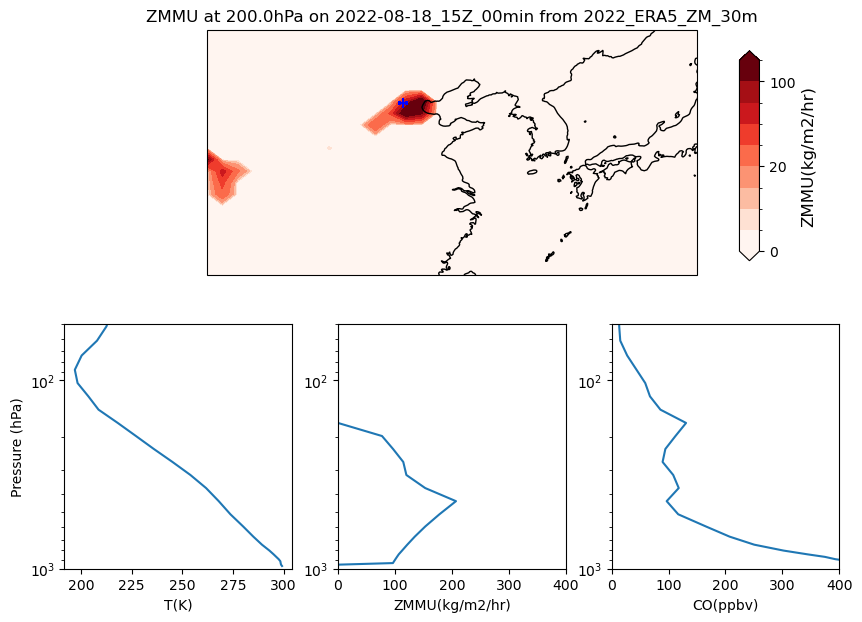

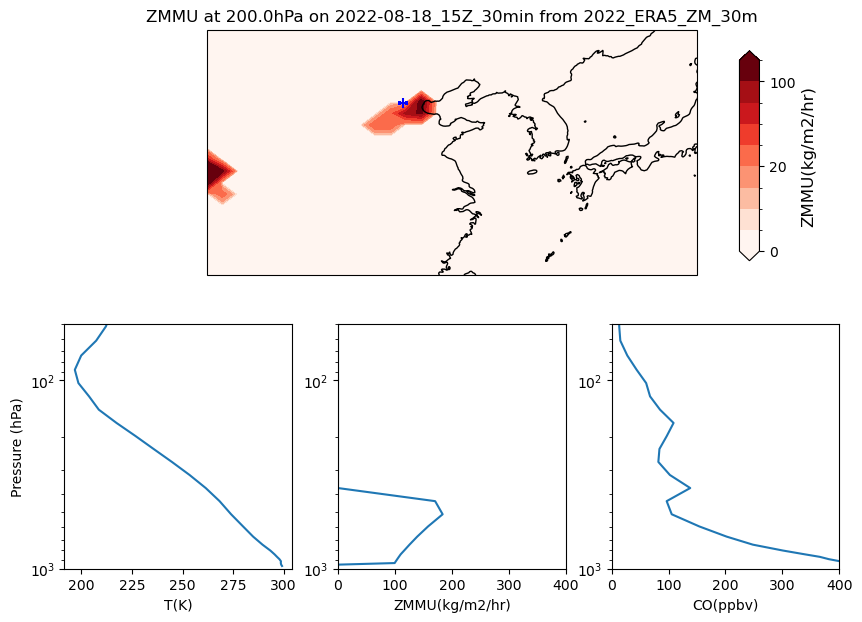

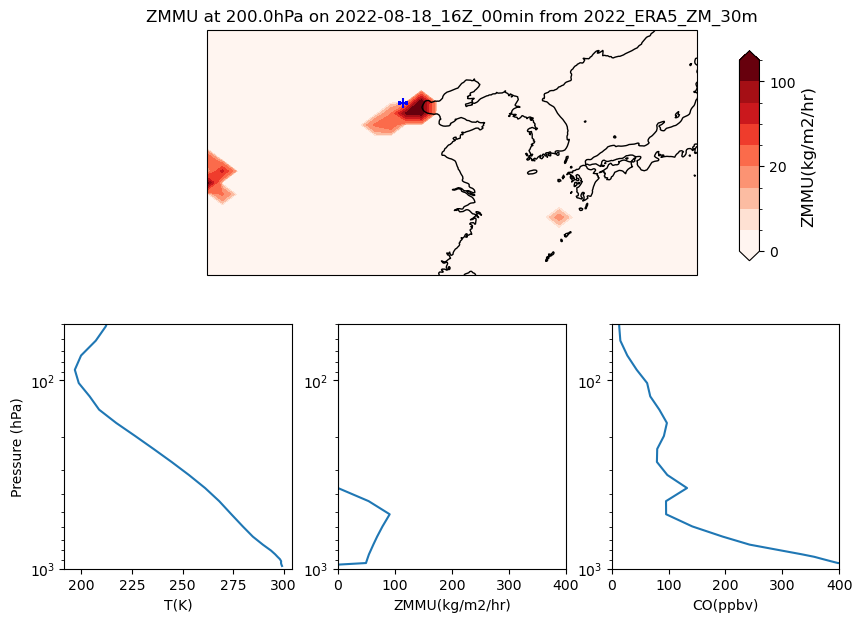

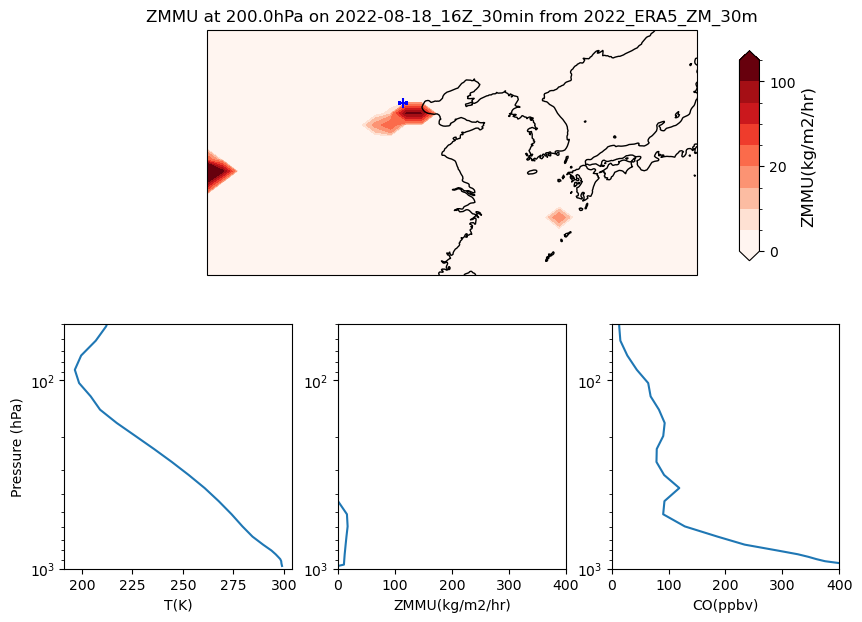

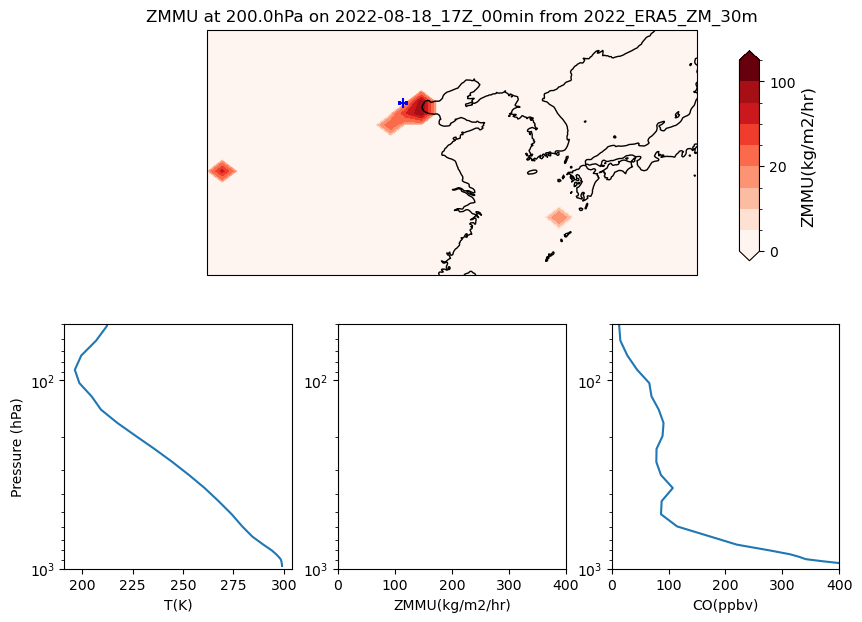

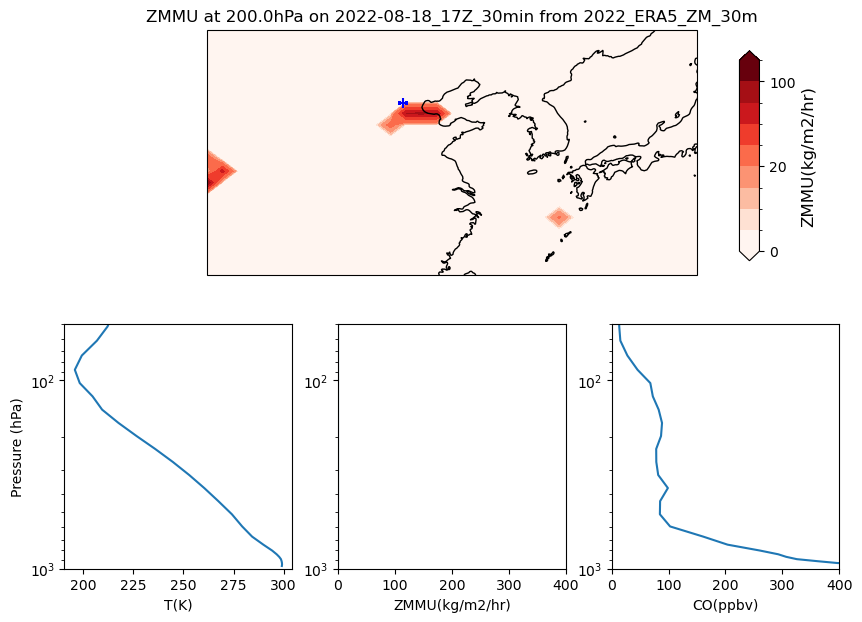

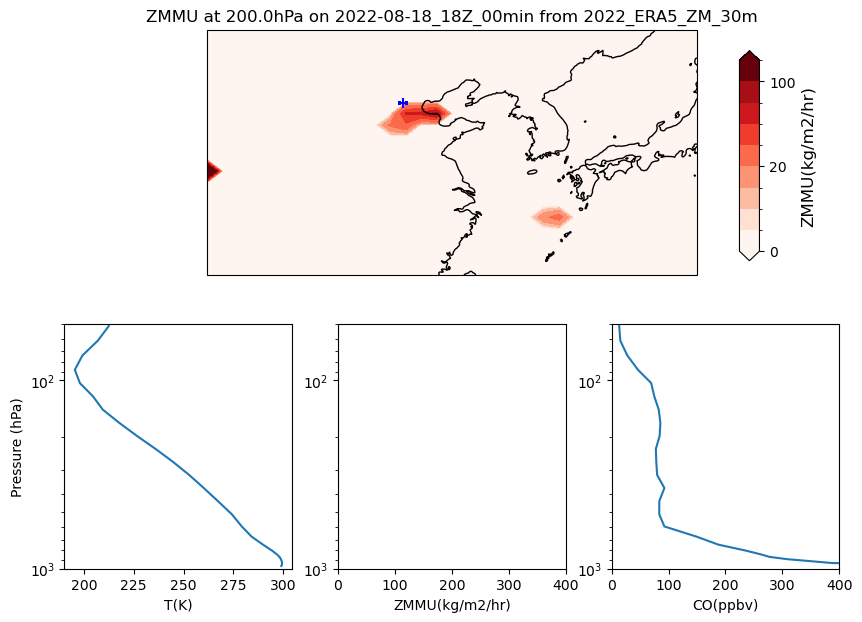

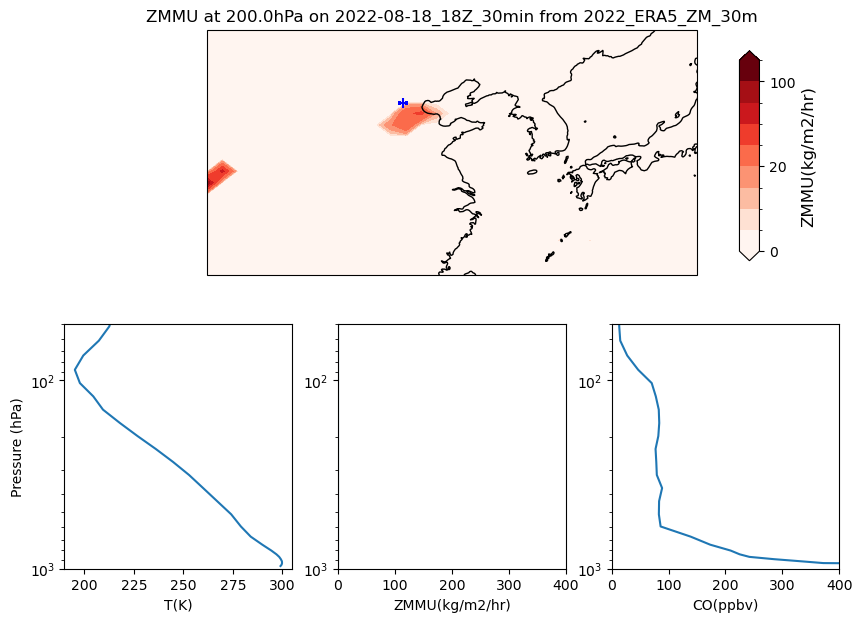

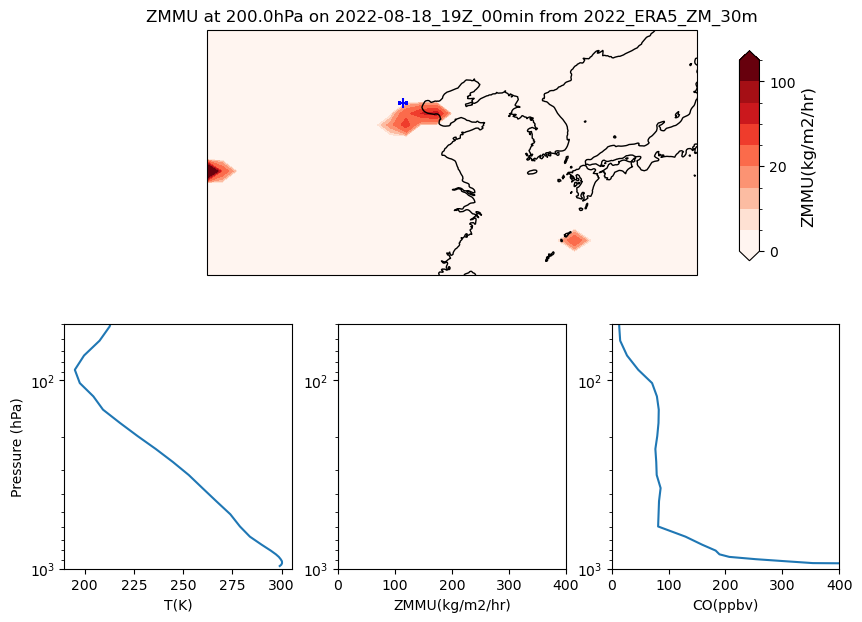

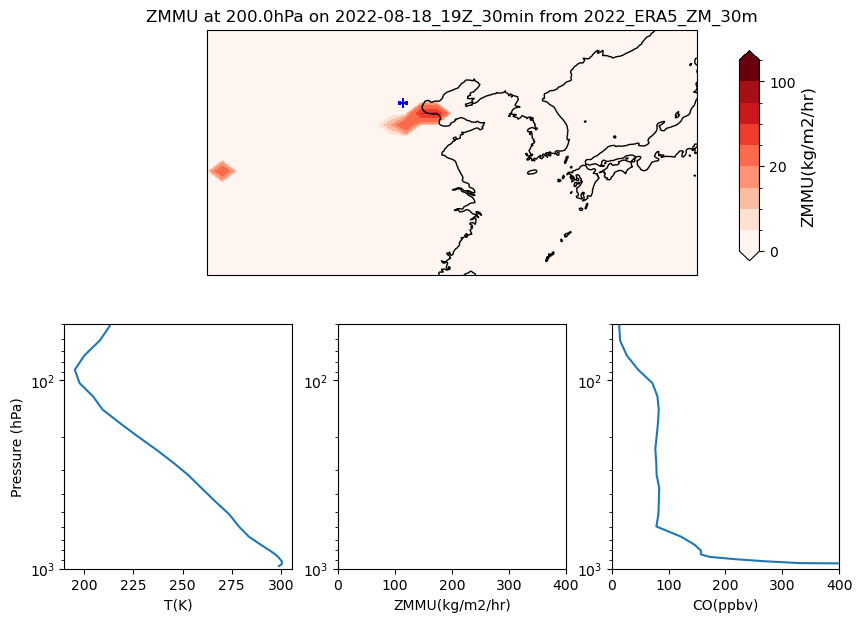

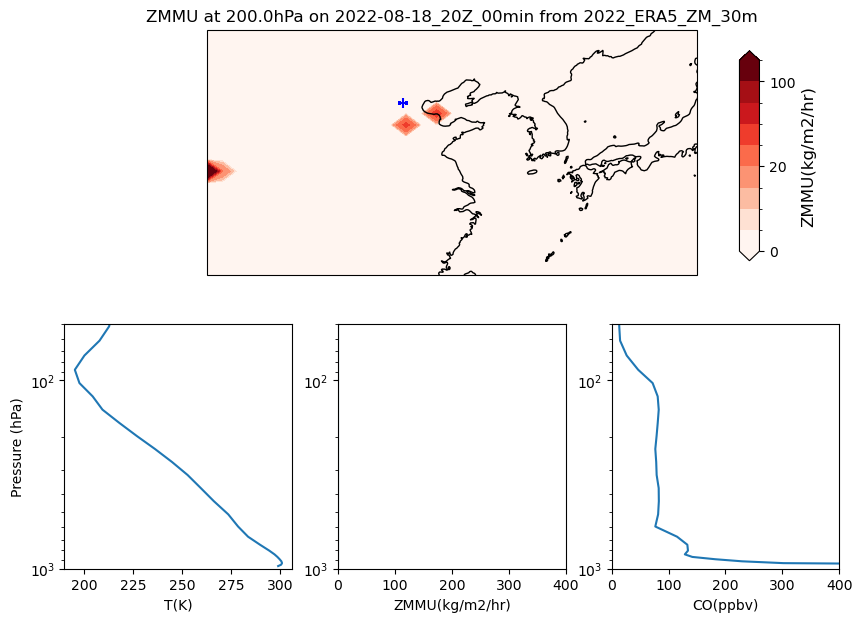

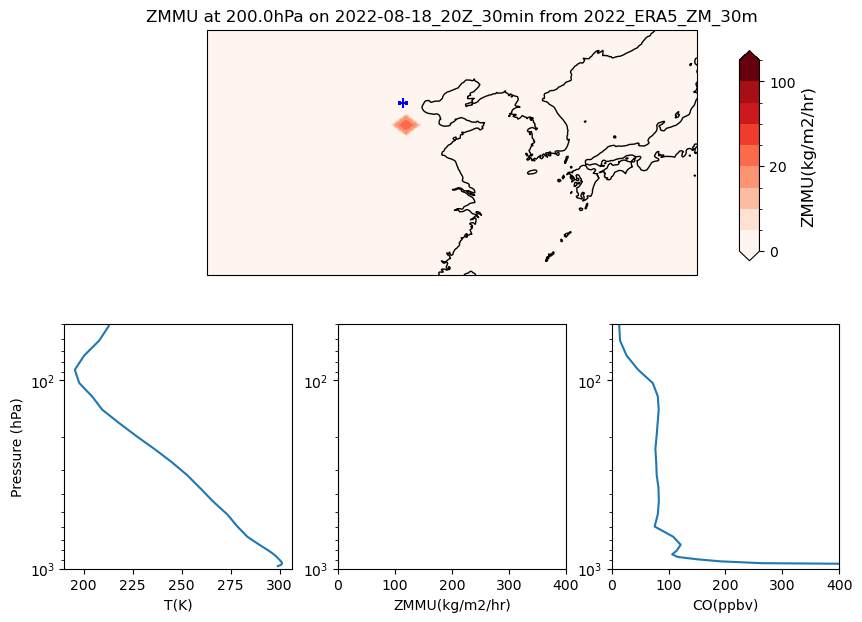

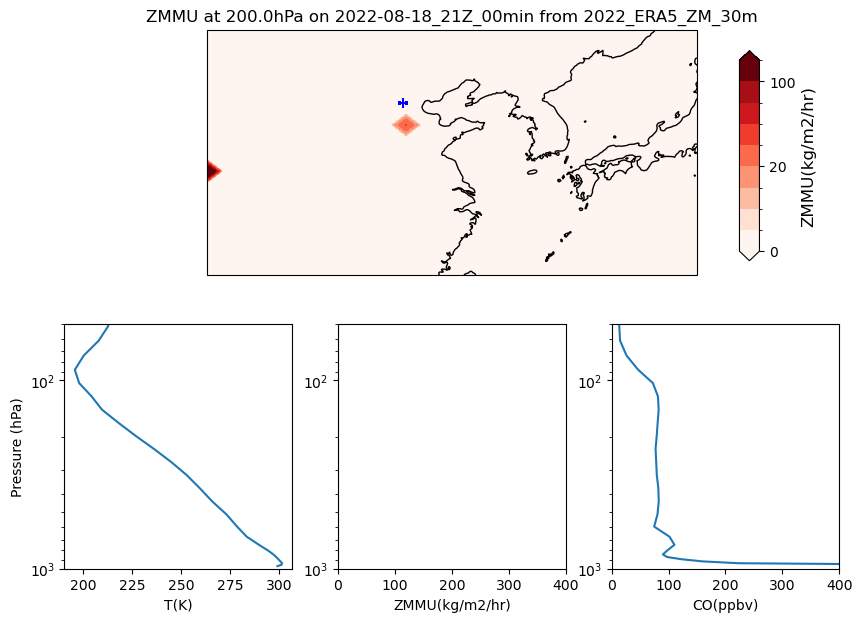

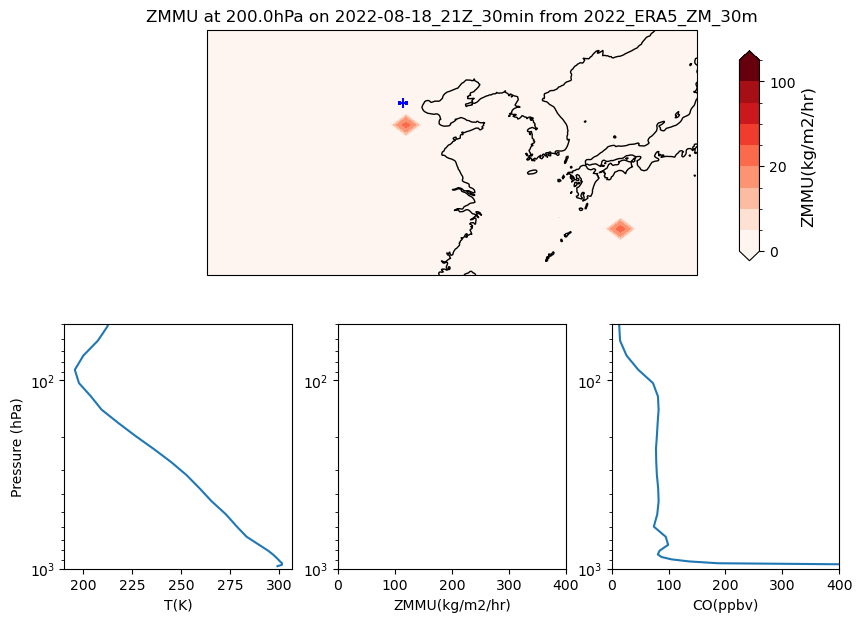

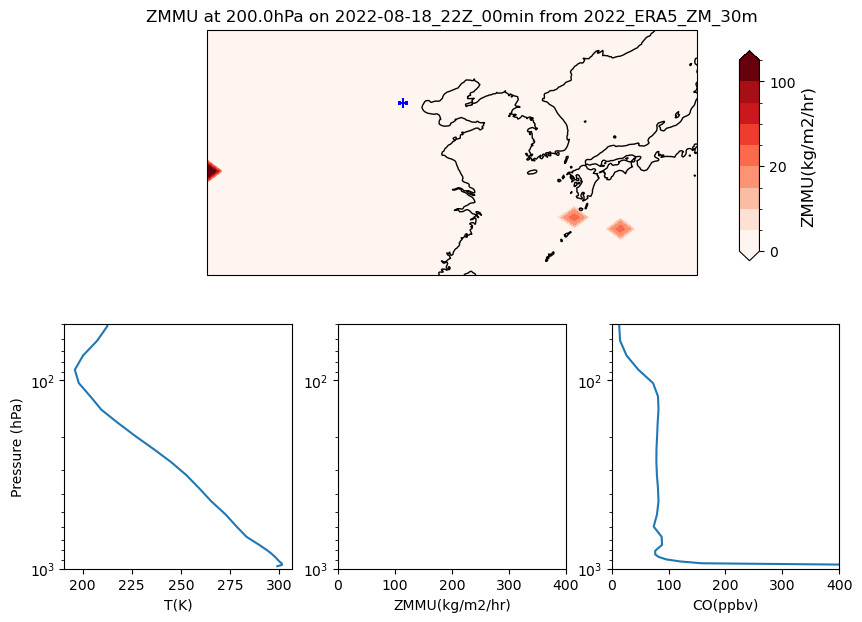

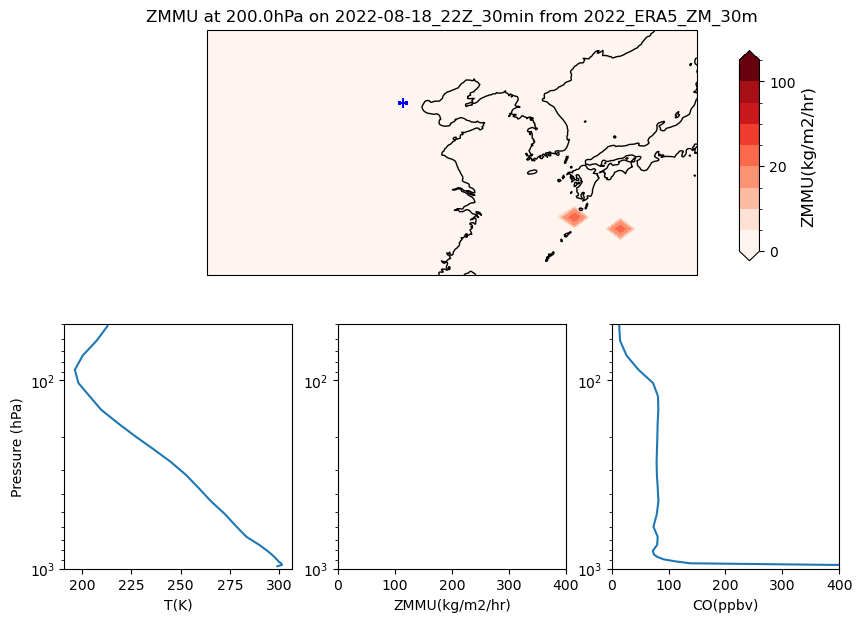

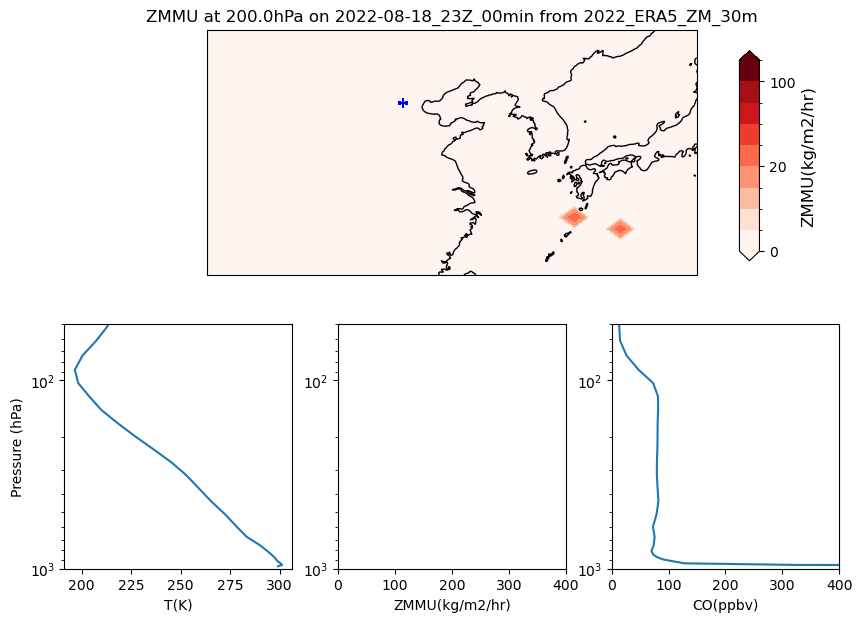

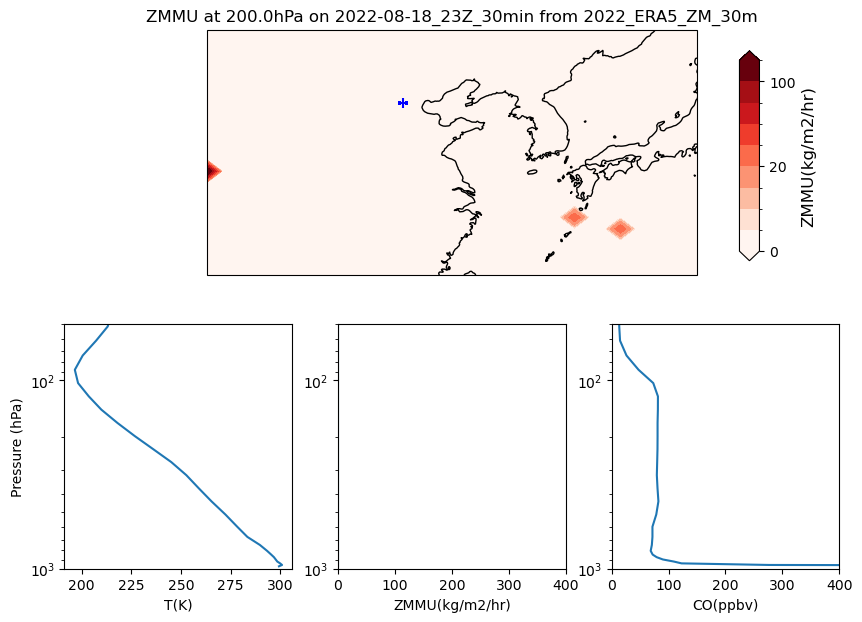

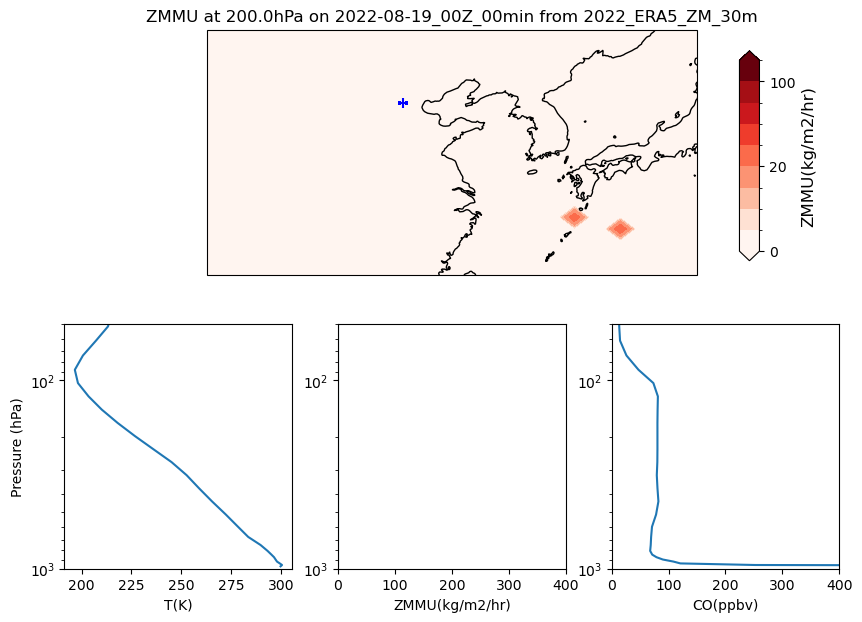

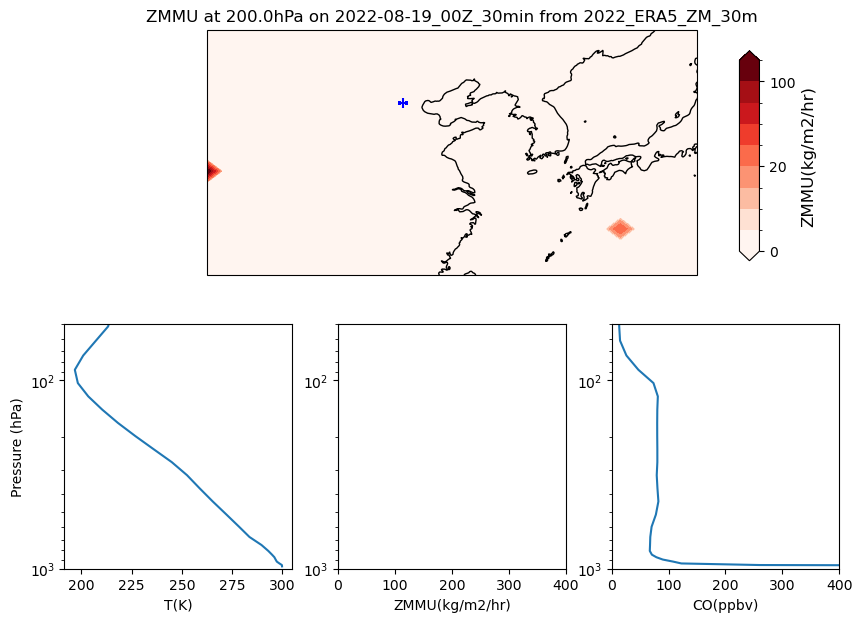

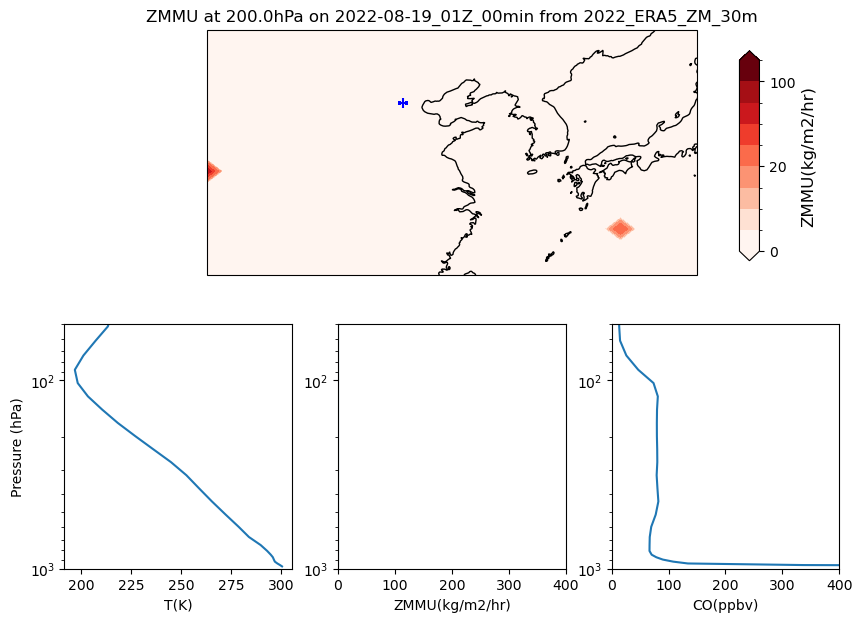

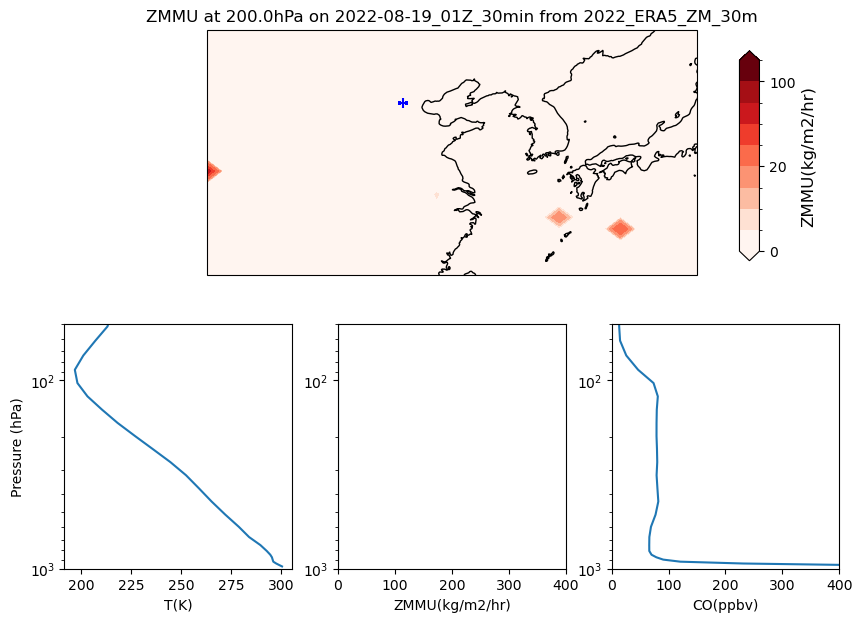

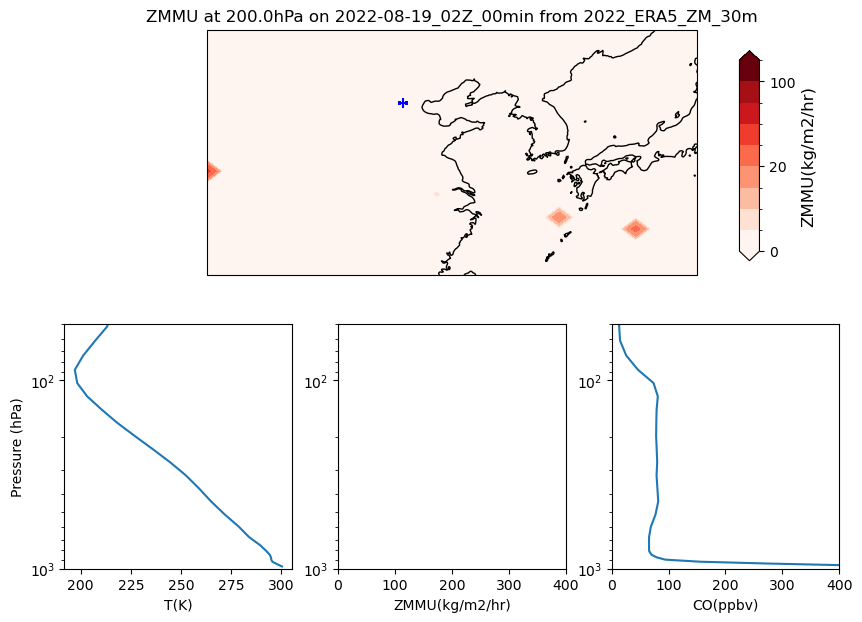

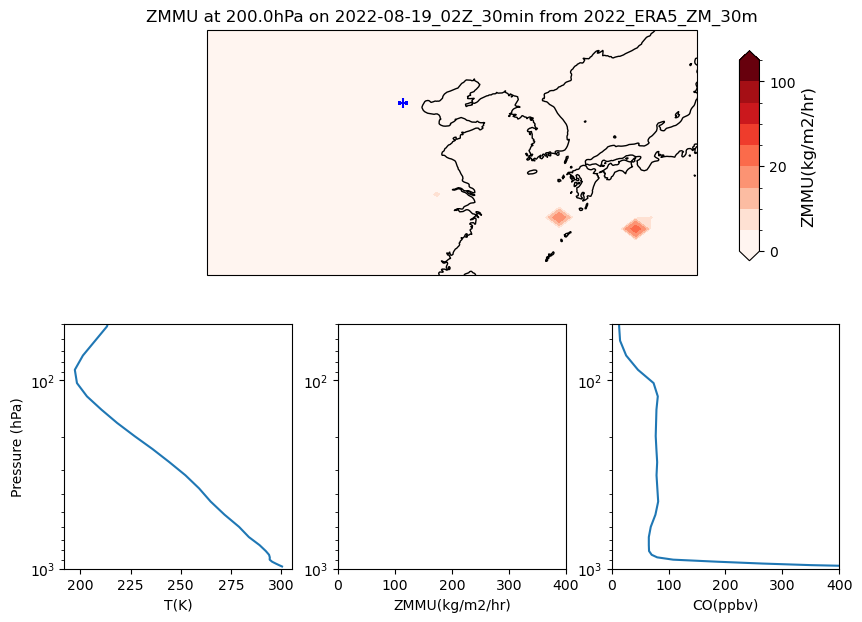

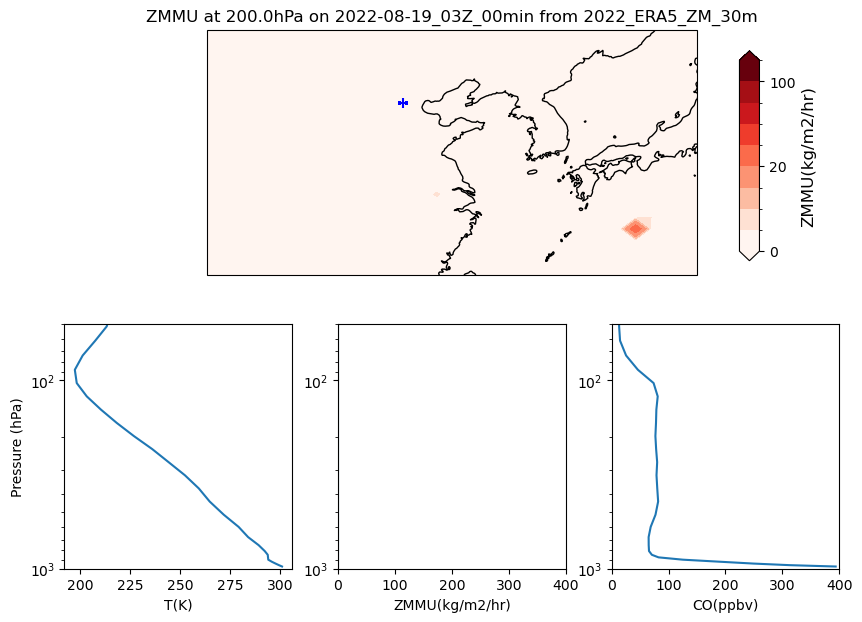

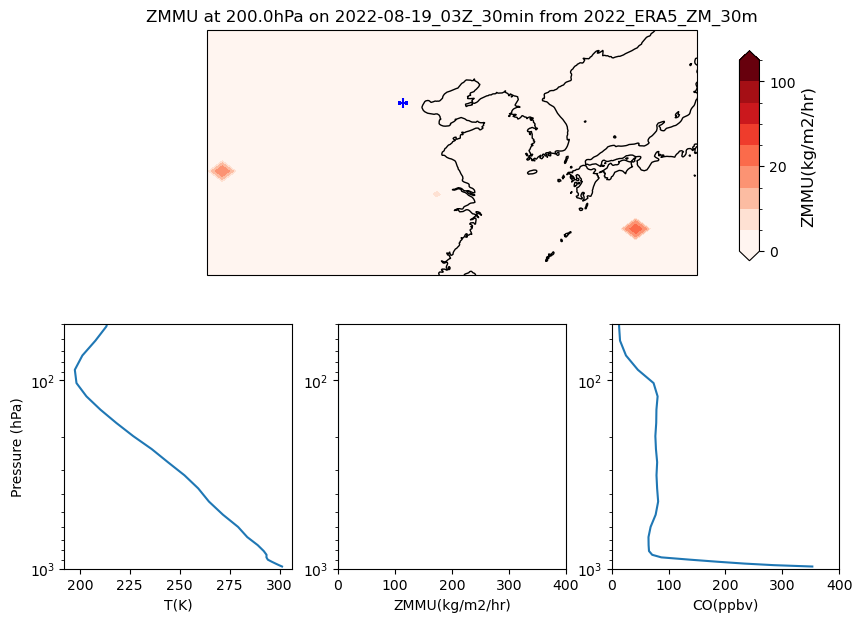

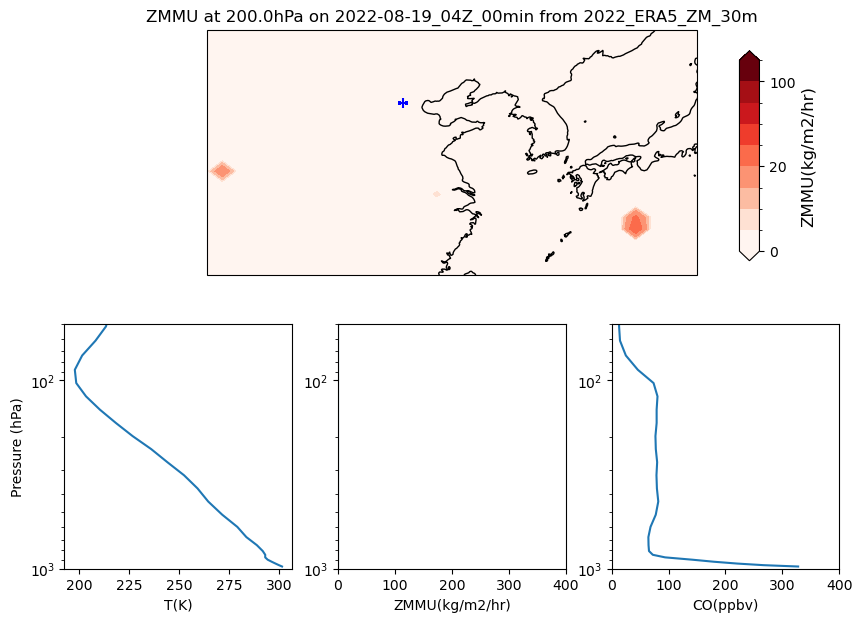

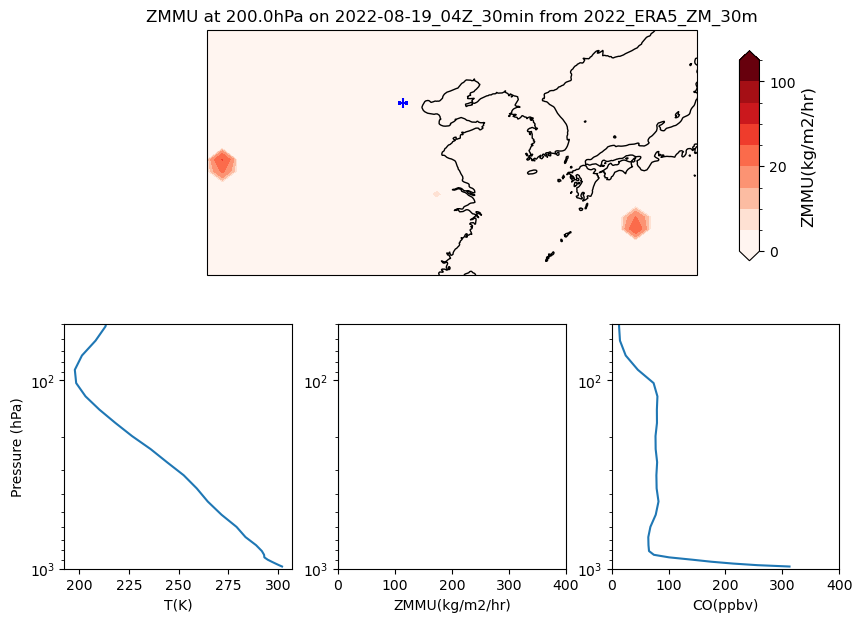

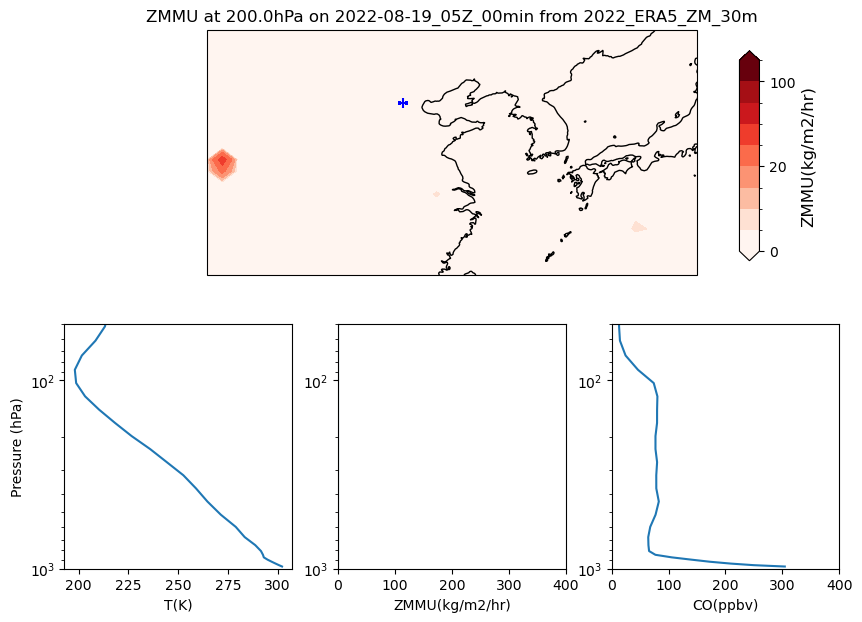

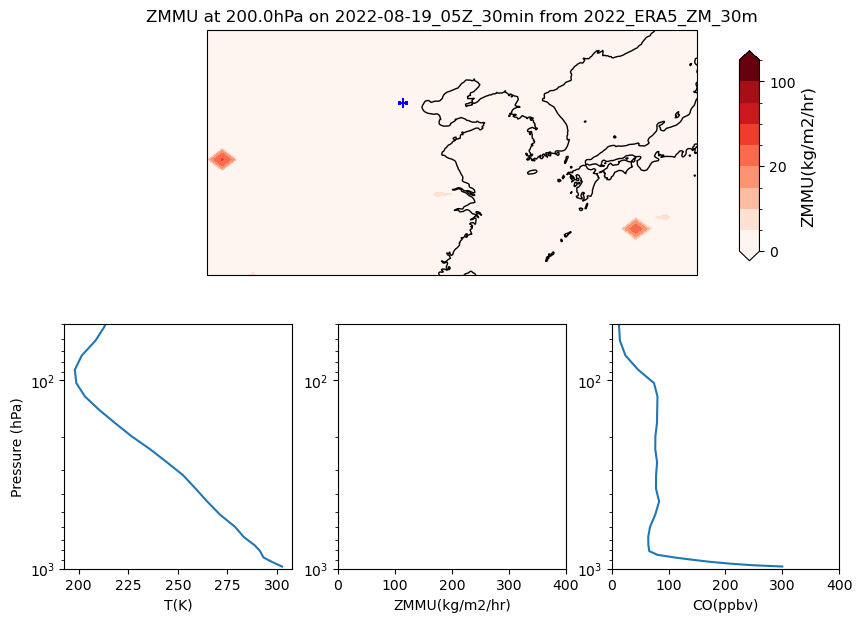

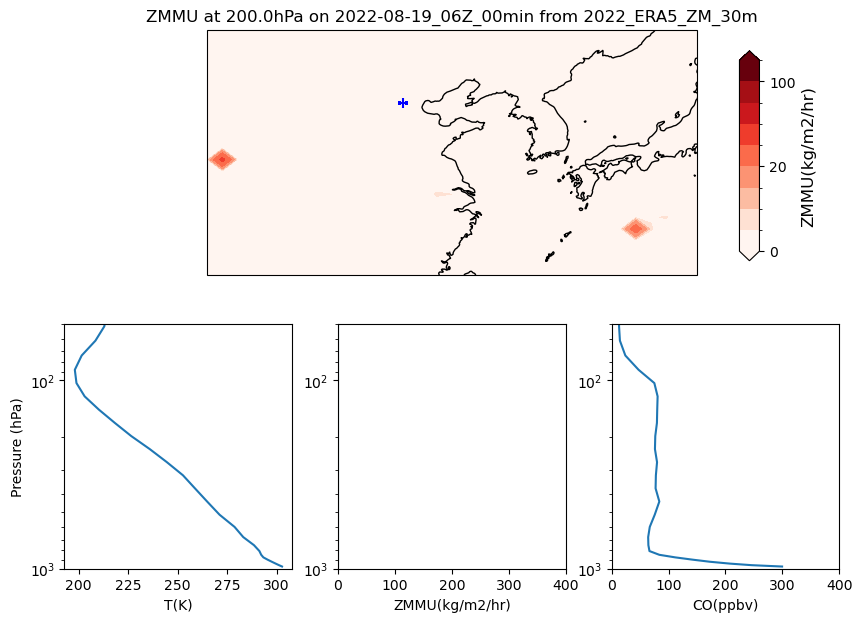

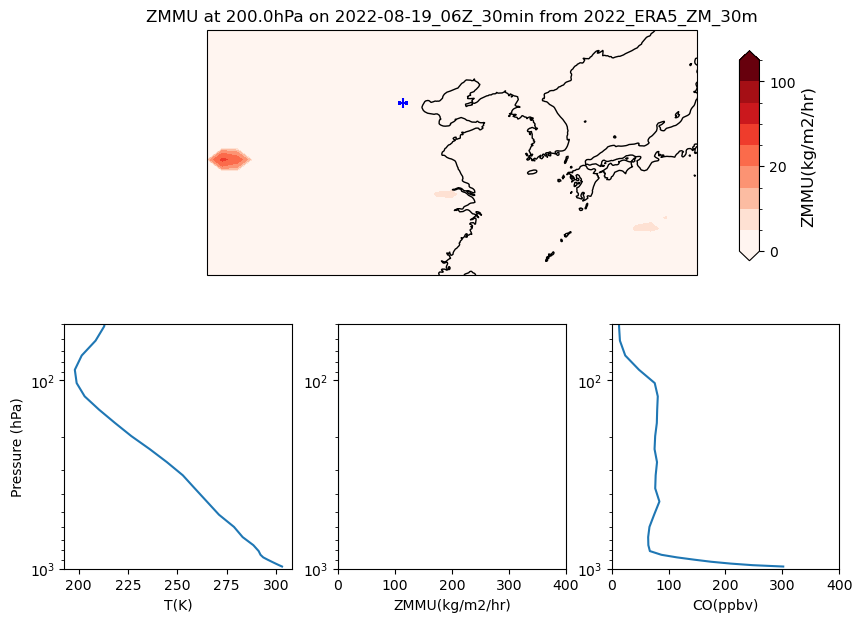

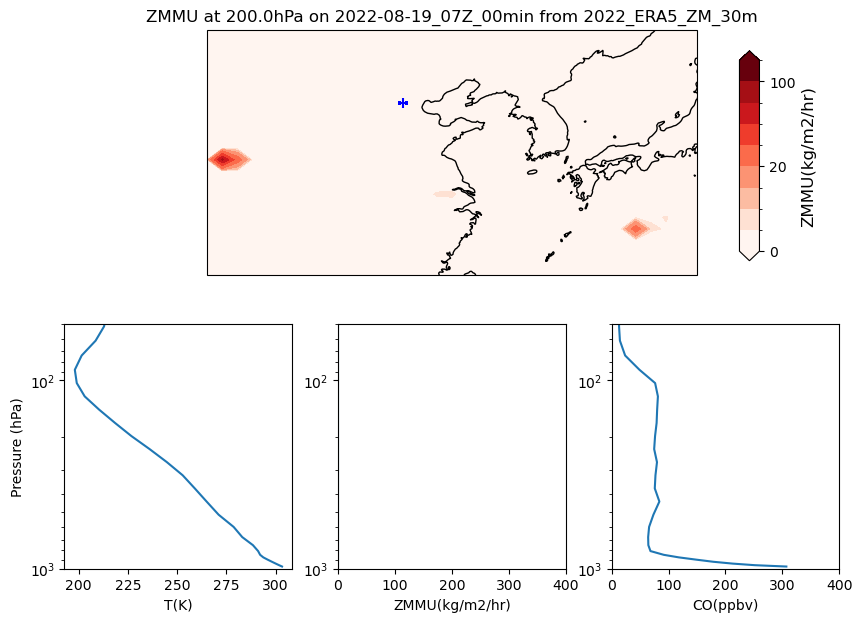

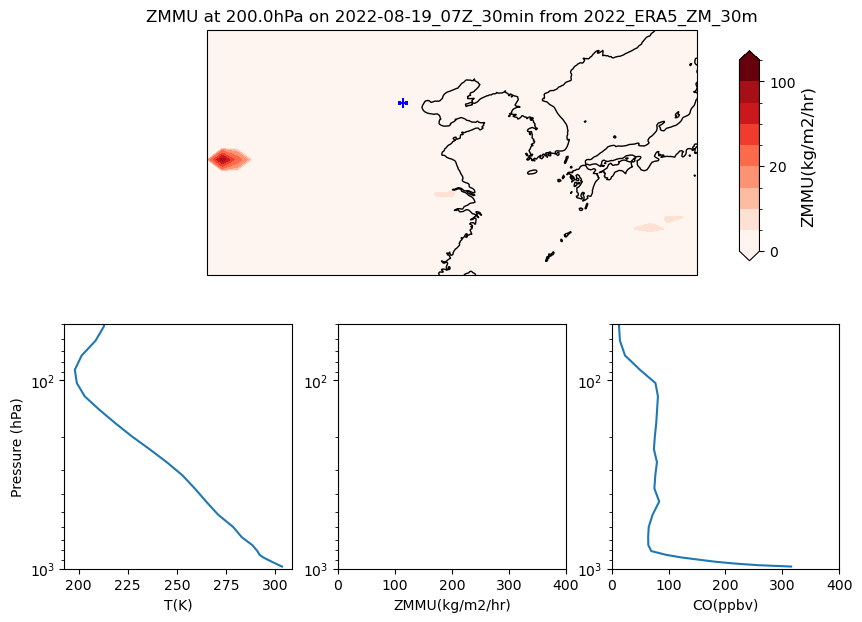

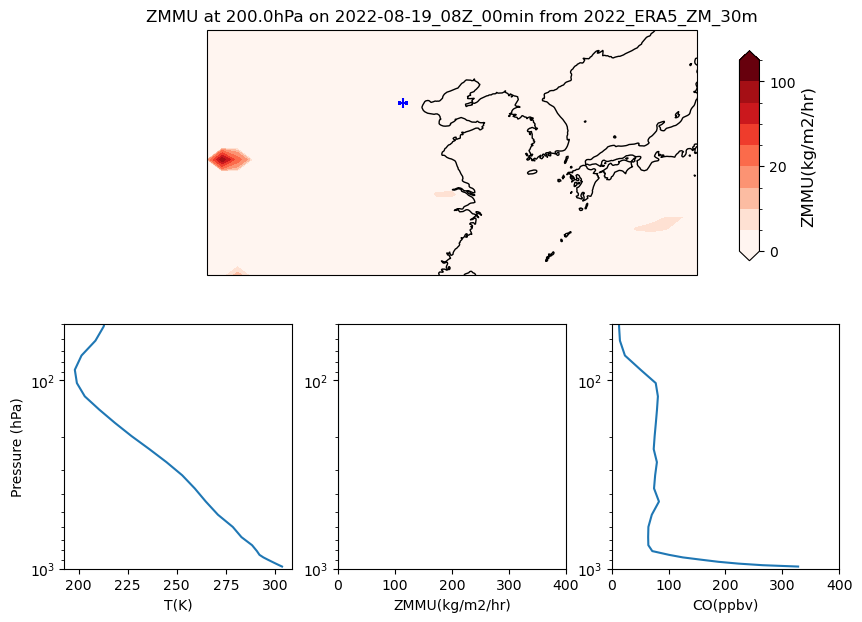

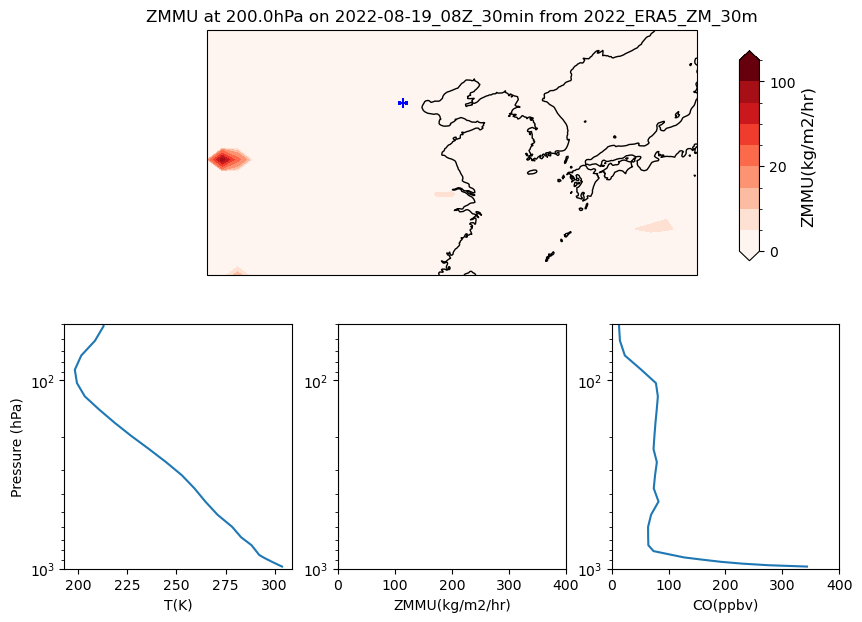

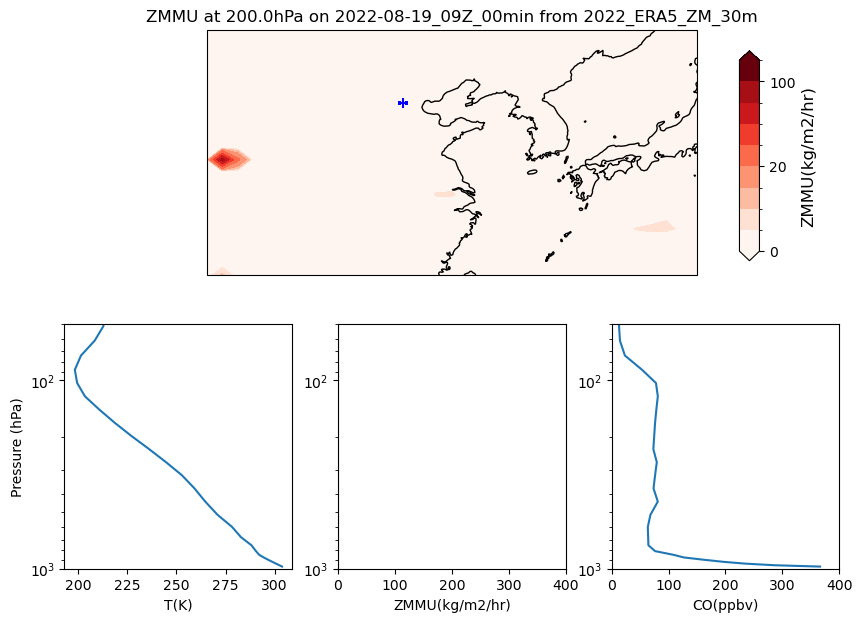

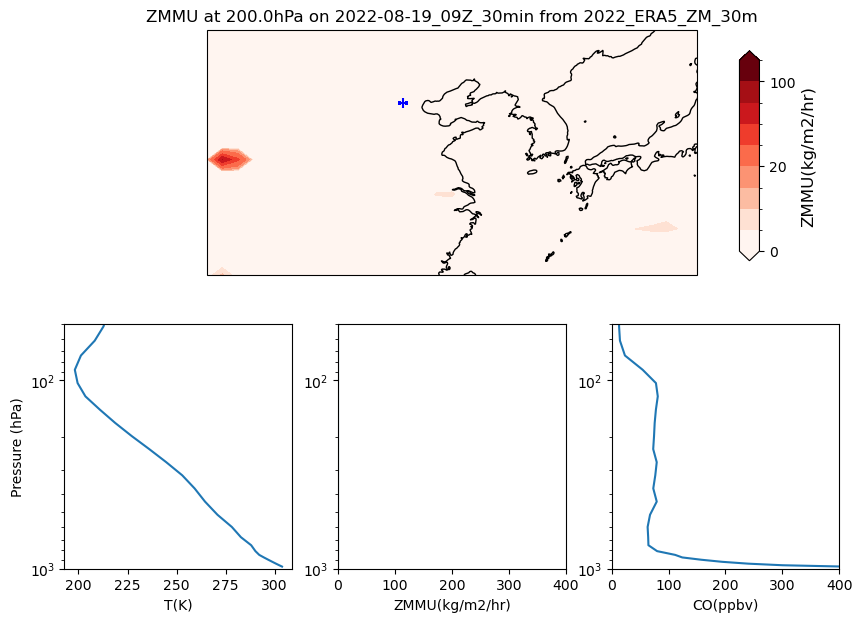

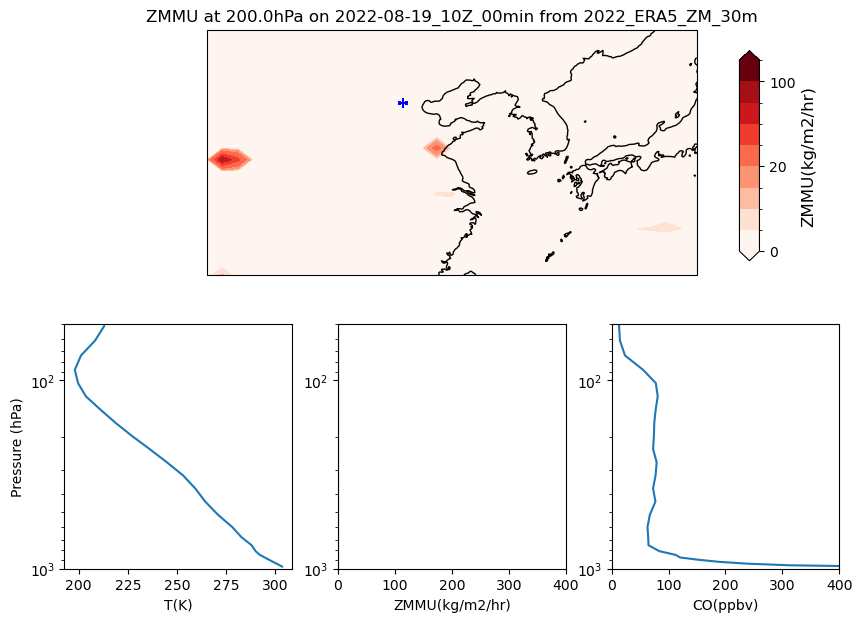

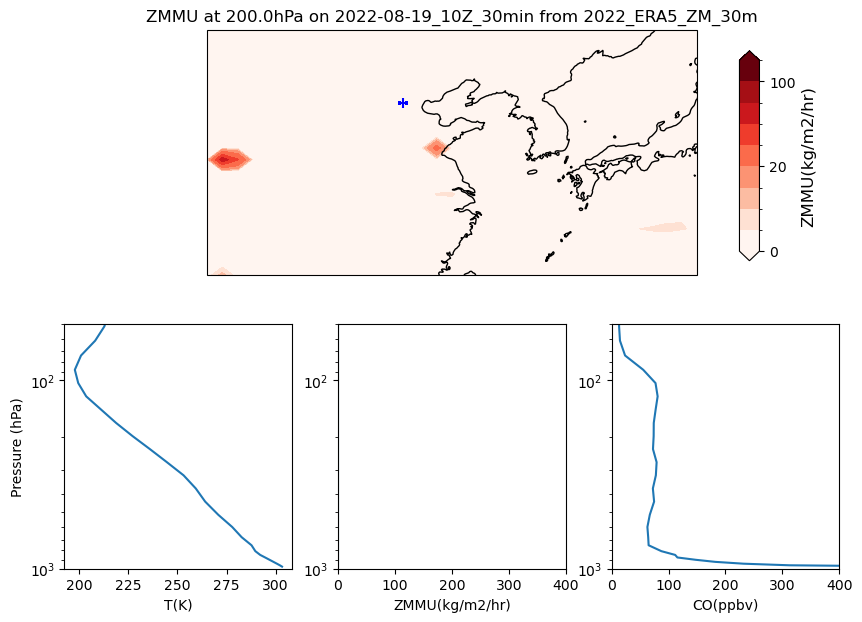

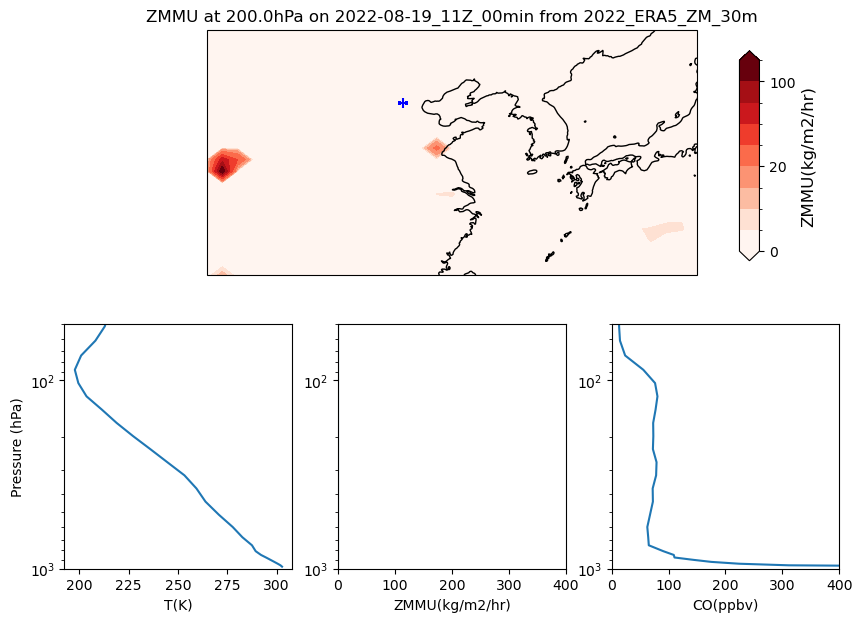

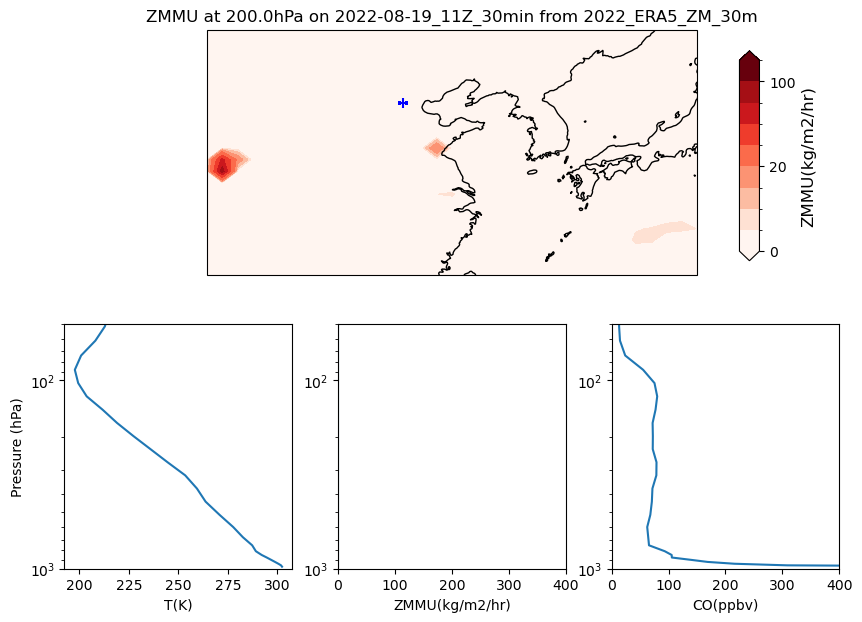

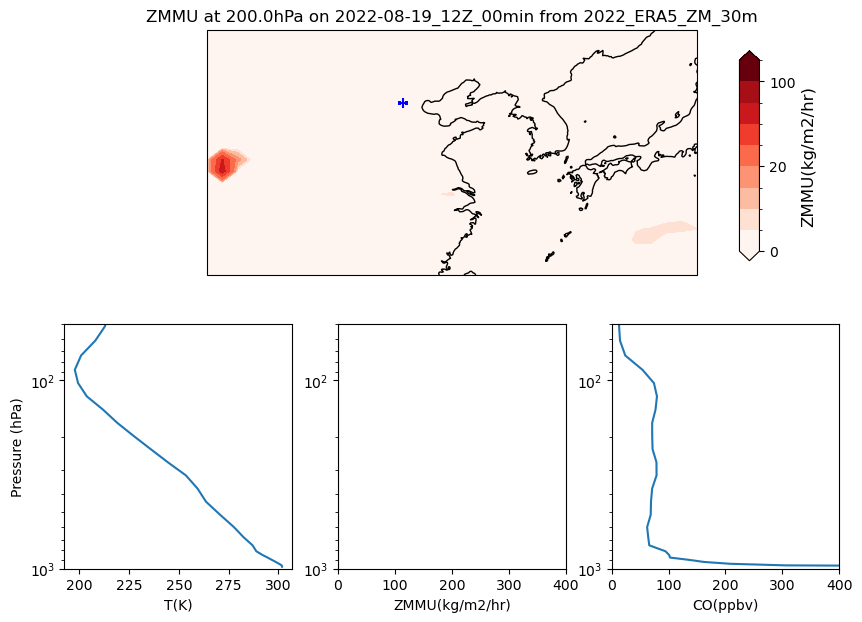

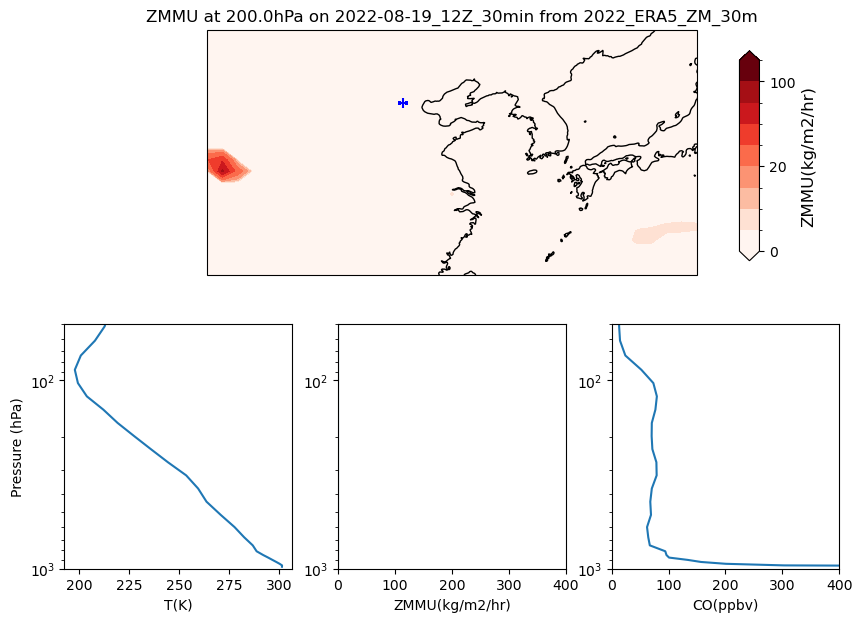

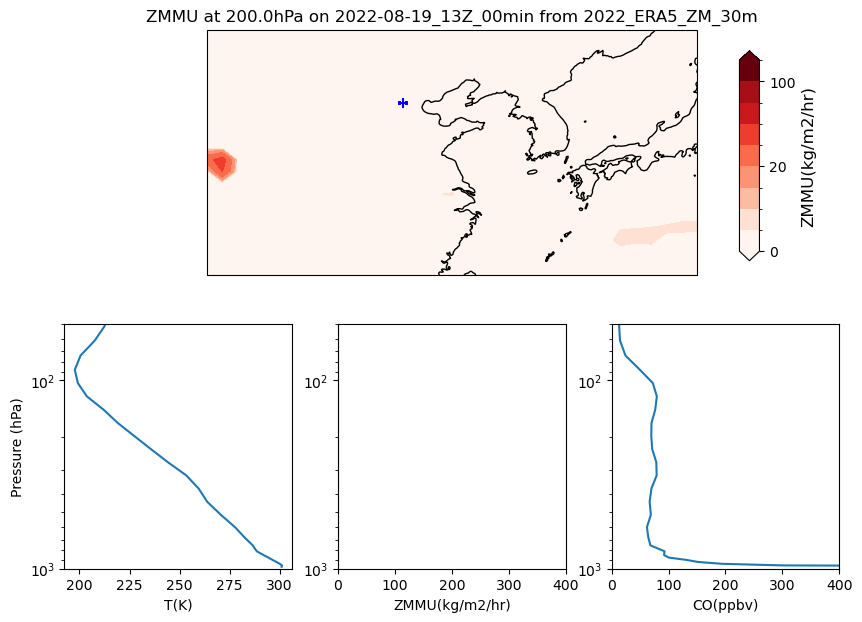

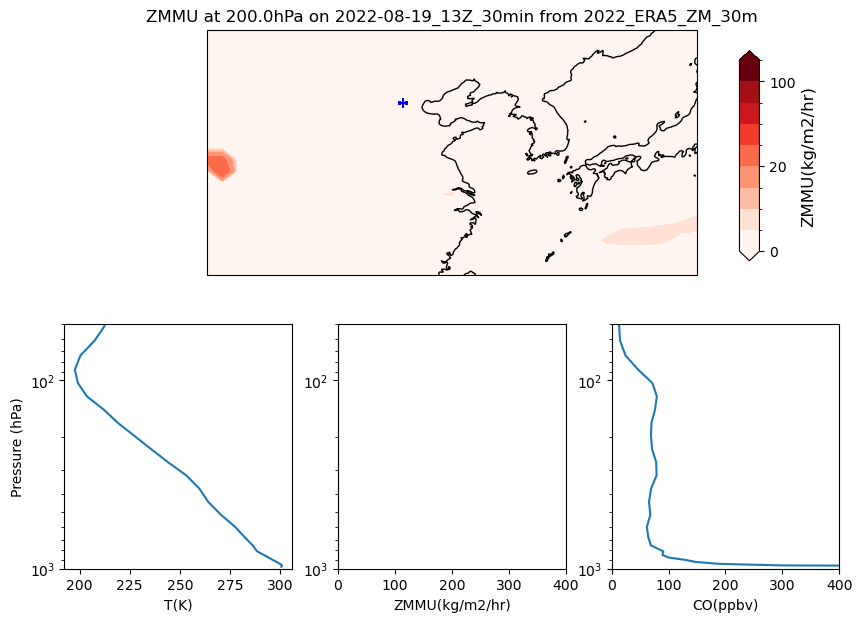

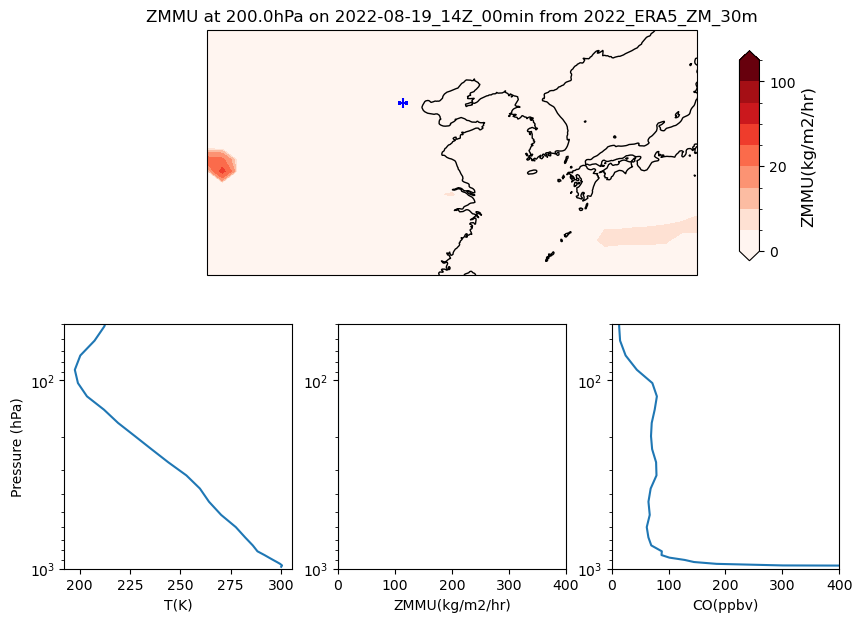

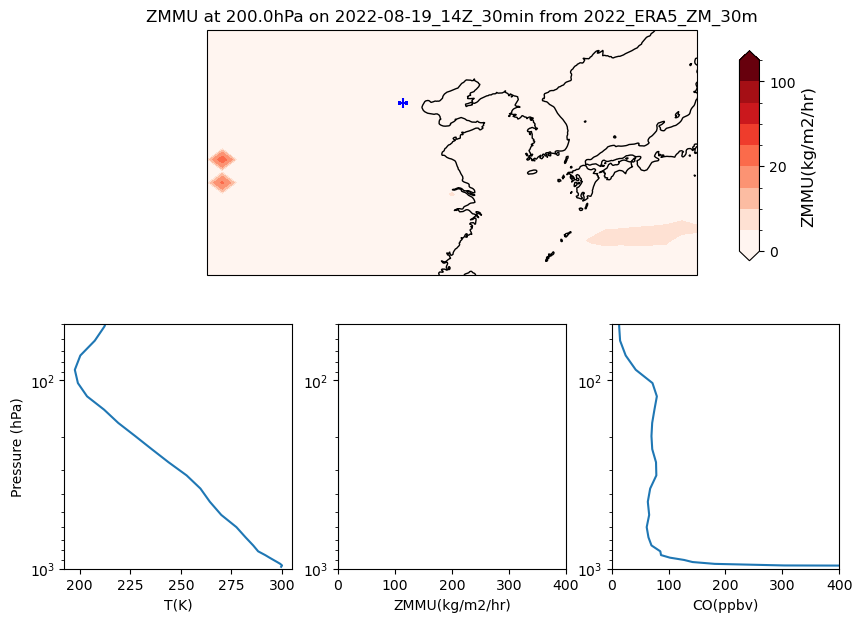

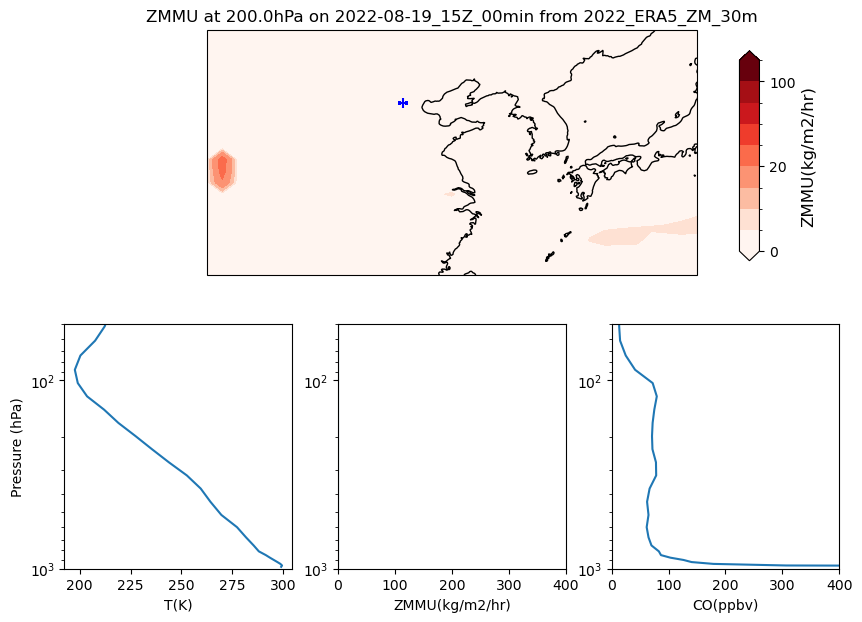

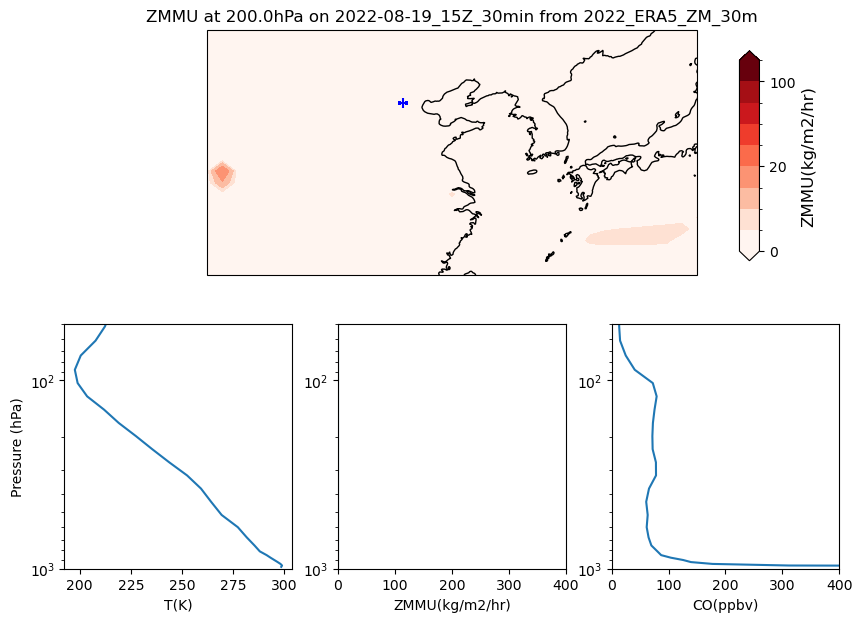

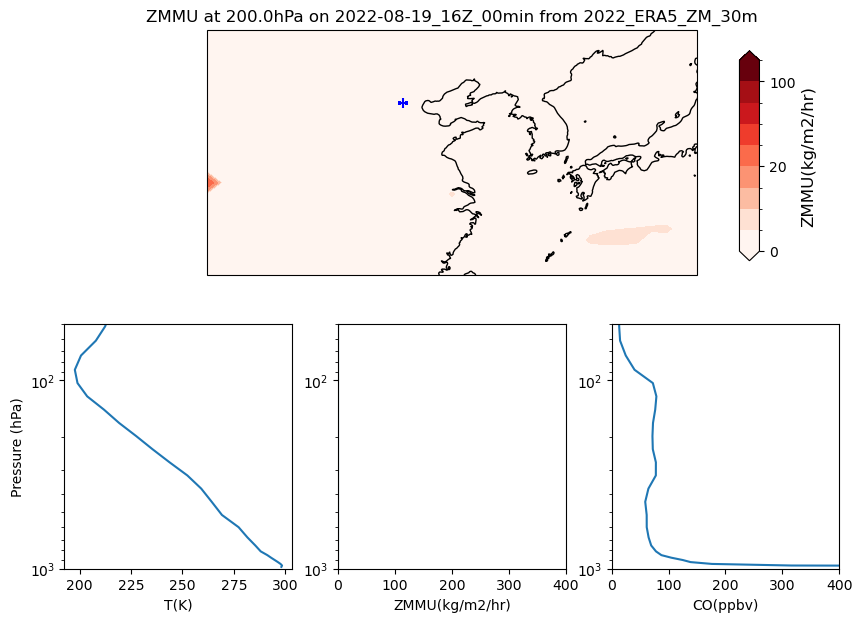

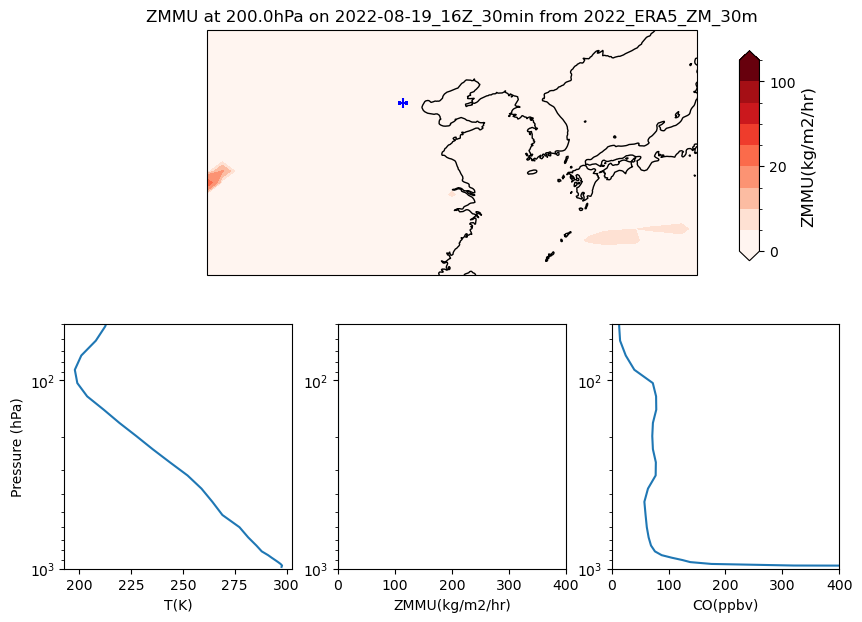

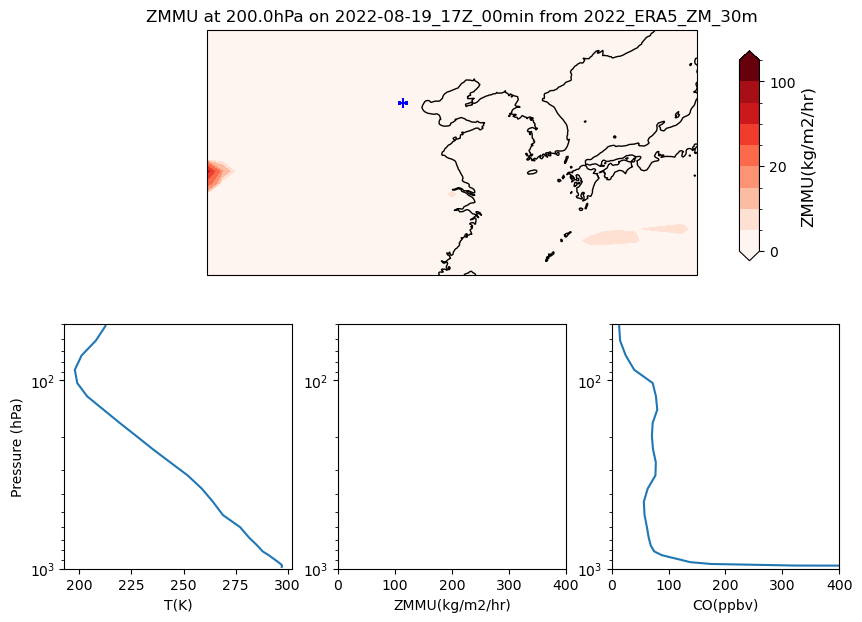

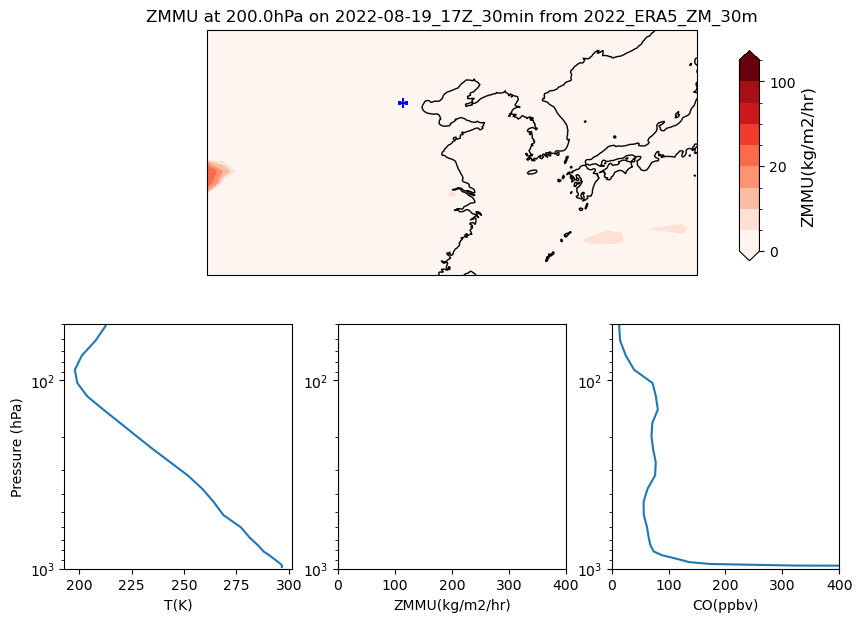

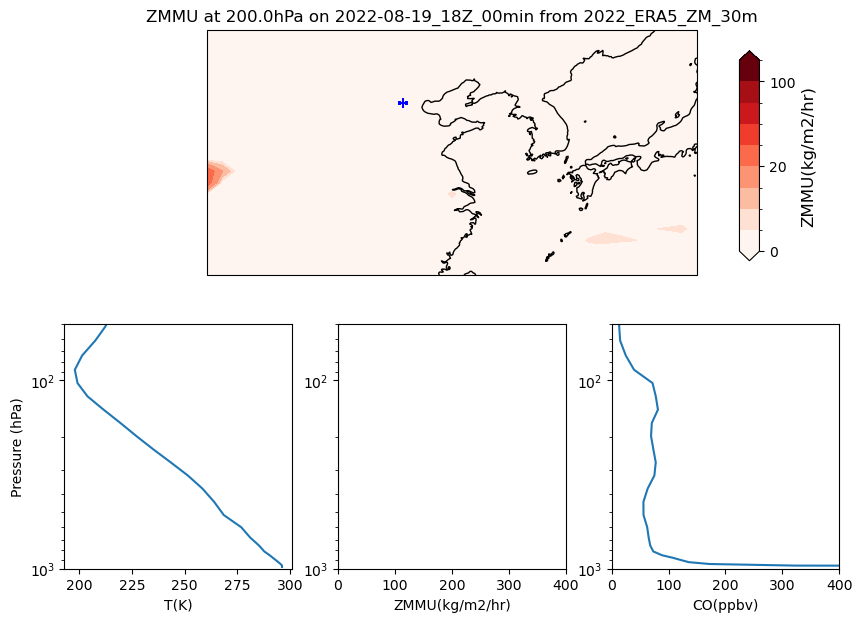

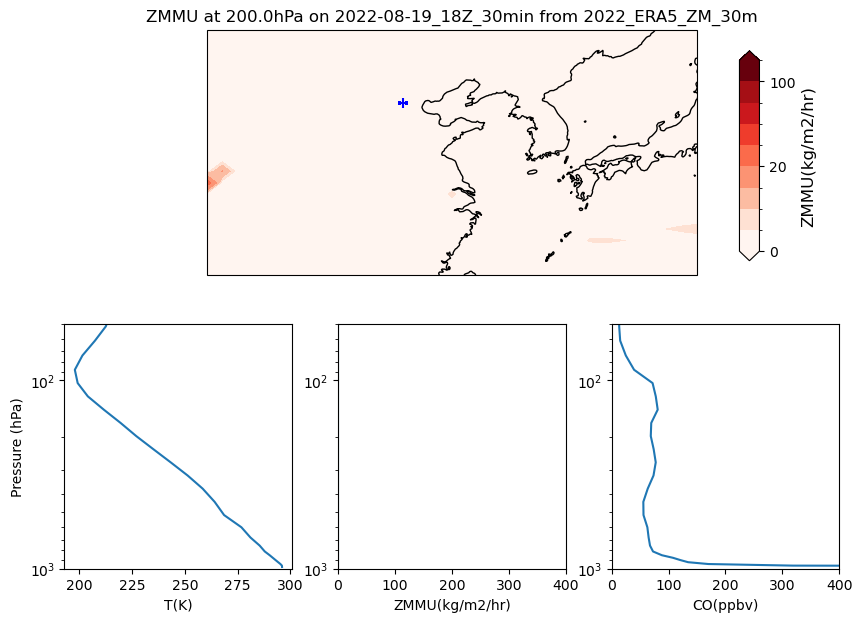

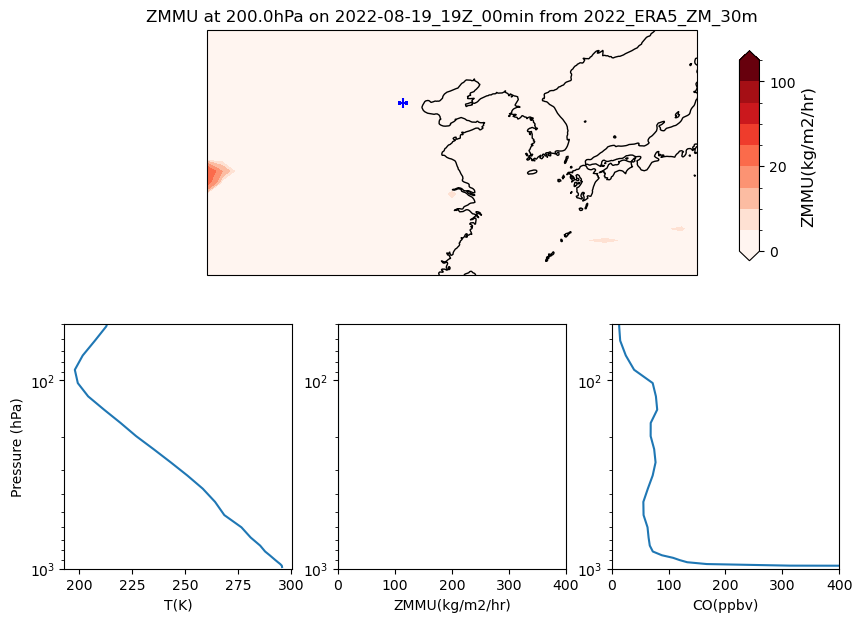

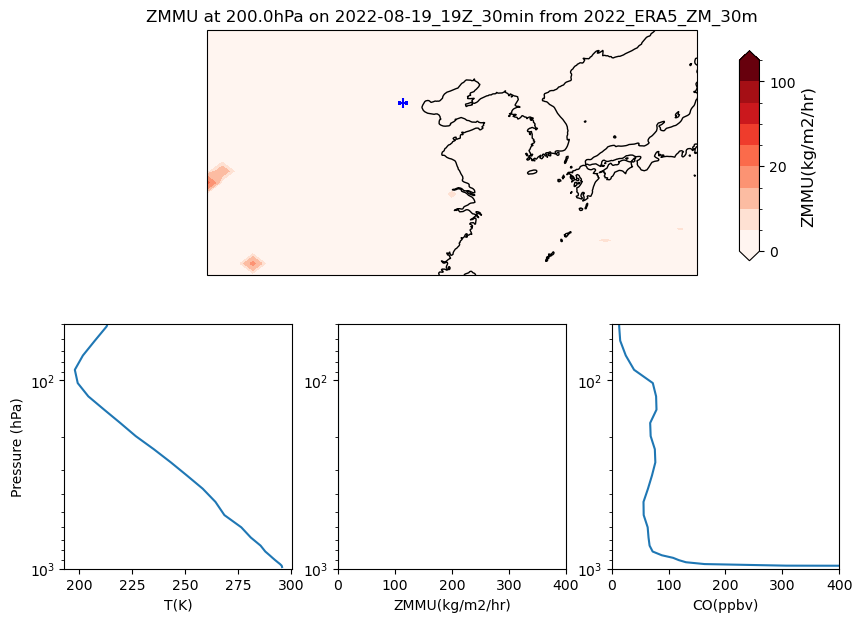

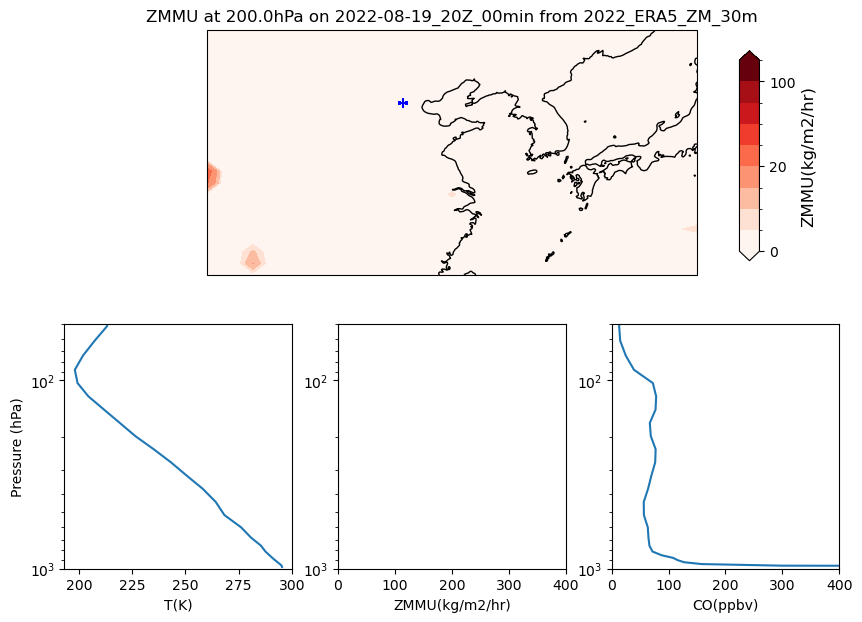

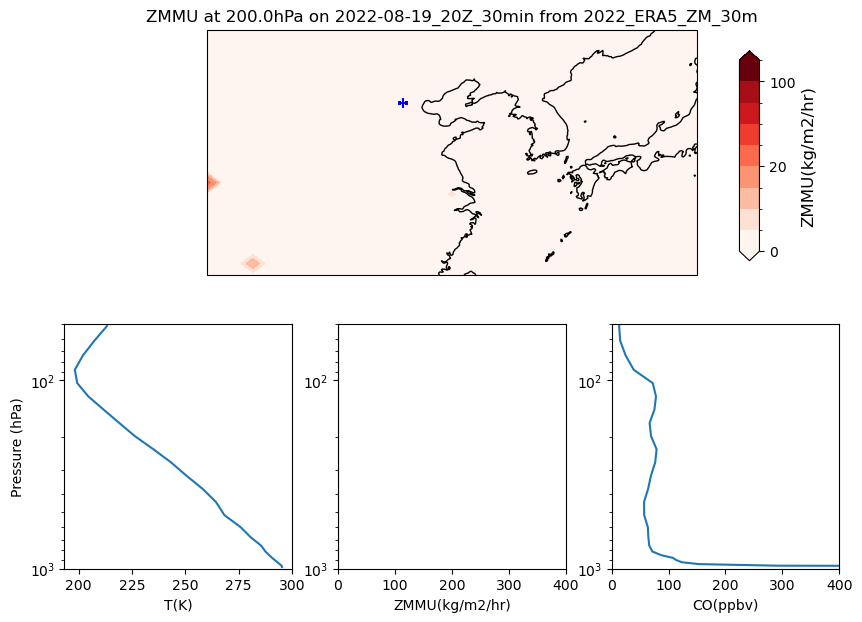

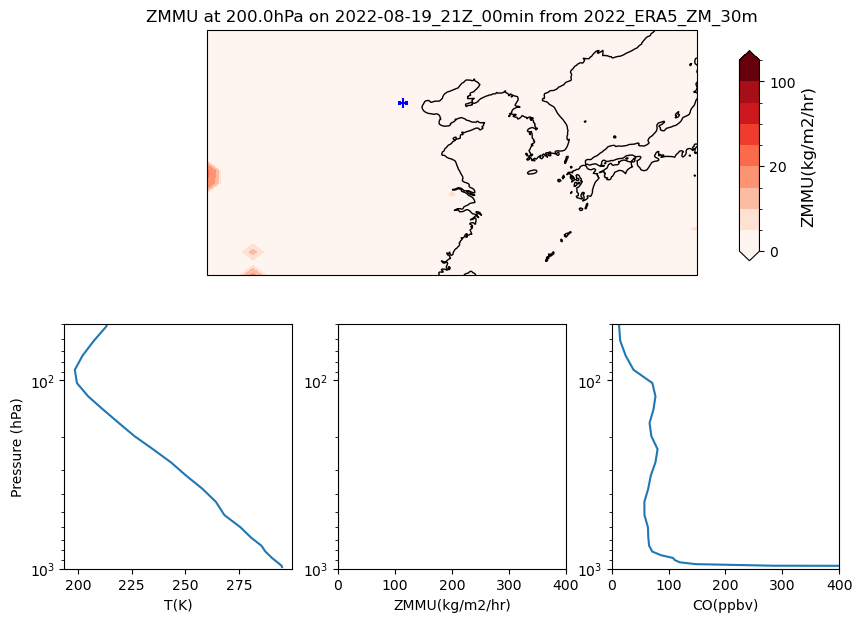

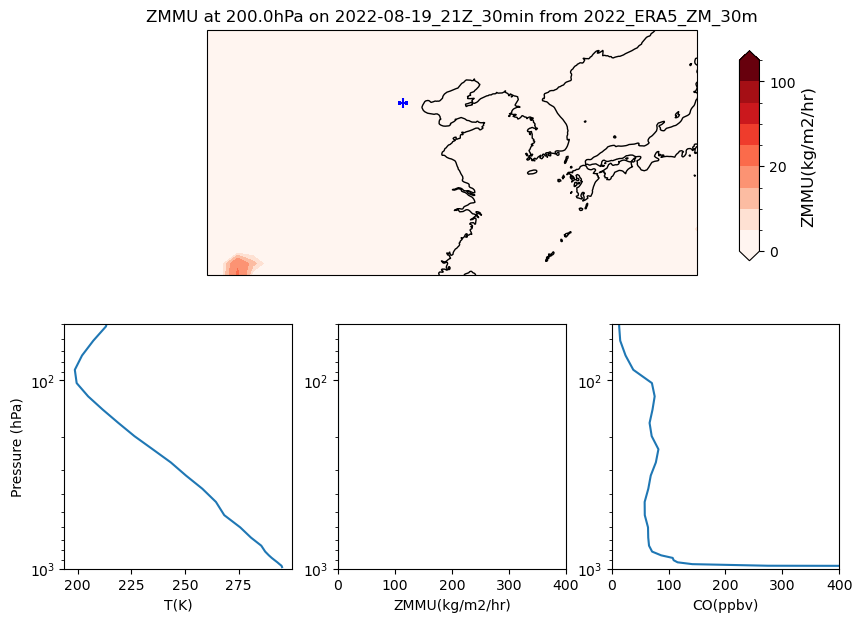

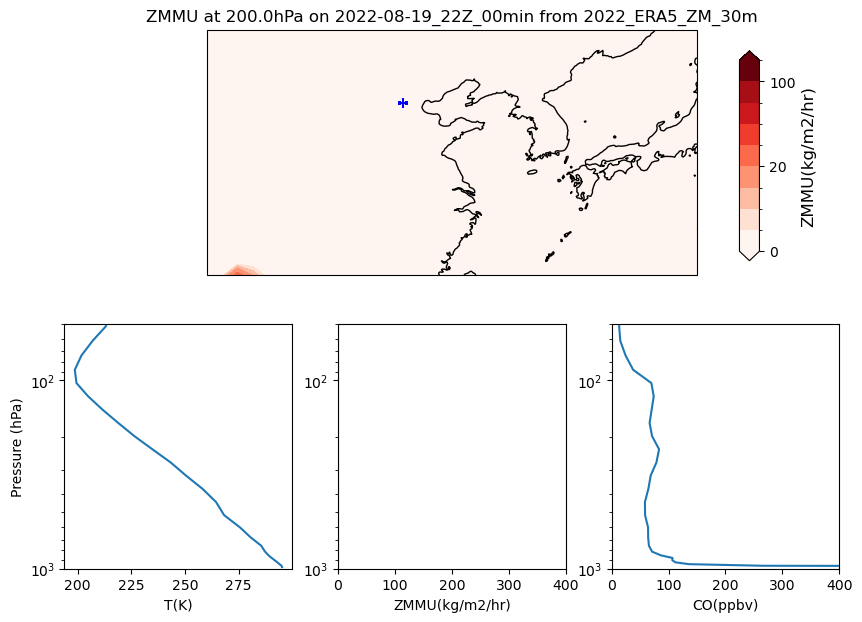

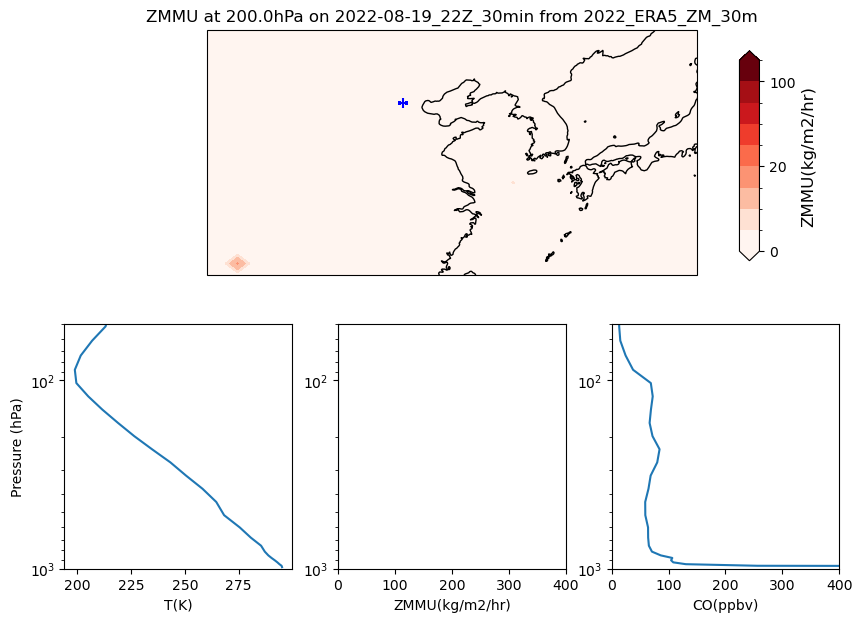

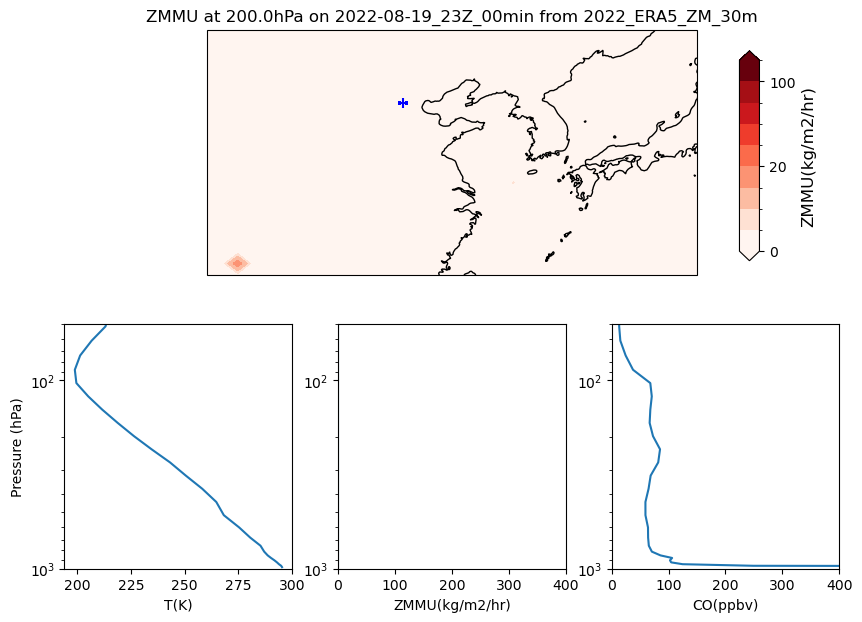

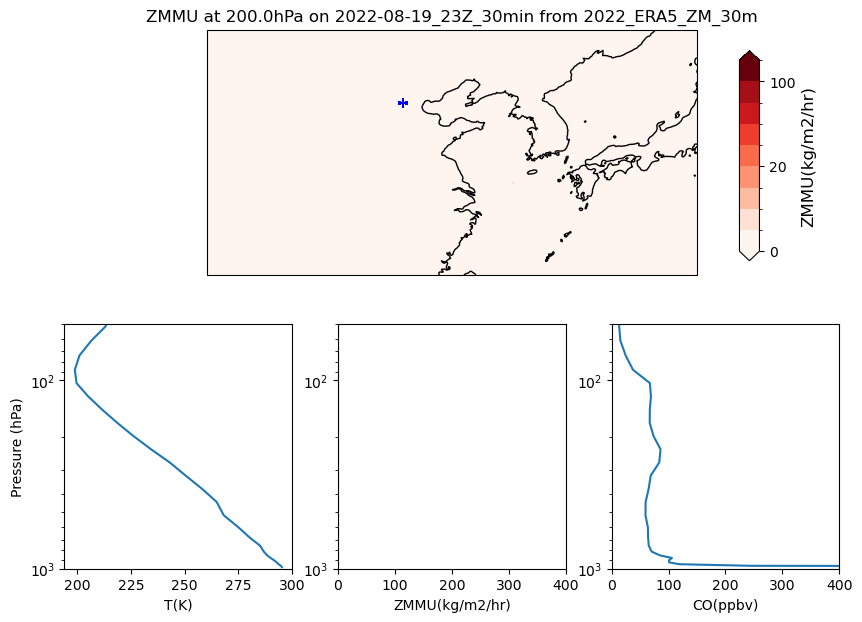

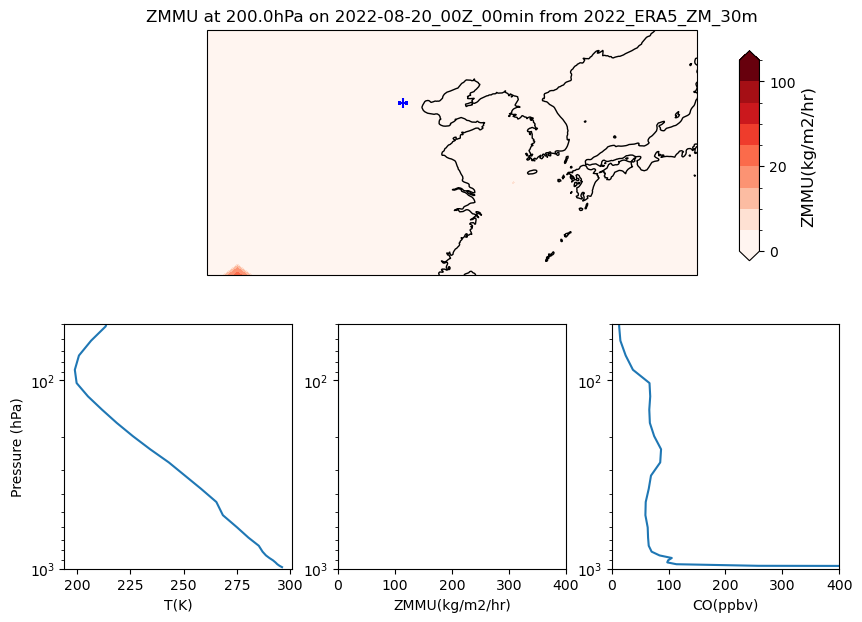

In [5]:

FILES = sorted(glob.glob(map.remap[sim]))   # Define all the file paths
    
# Go file-by-file to generate plots
#for FILE in FILES:      
for FILE in FILES[136:152]:

    print(FILE)
    print('File ', FILES.index(FILE))
    
    ncfile = nc4.Dataset(FILE)
    dates = ncfile.variables['date'][:]
    datesec = ncfile.variables['datesec'][:]
        
    var_plot_levs = pc.var_info[plot_var]['plot_levs']
    var_cross_sects = pc.var_info[plot_var]['cross_sects']
    var_strs = pc.var_info[plot_var]['vars']
    var_mod = pc.var_info[plot_var]['mod']
            
    # Loop over all the time steps in the current file
    for t in range(len(dates)):        

        # Define the date string at the time the plot is valid for
        valid_datestr = str(dates[t])[0:4] + '-' + str(dates[t])[4:6] + '-' + str(dates[t])[6:8] \
        + '_' + str(int(datesec[t]/3600.)).zfill(2) + 'Z_' + str(int((datesec[t]/60.) % 60)).zfill(2) + 'min'            

        # Create the figure and add axes
        fig = plt.figure(figsize=(10,7))
        axmap = fig.add_subplot(2,3,(1,3), projection = ccrs.PlateCarree())
        axp1 = fig.add_subplot(2,3,4)
        axp2 = fig.add_subplot(2,3,5)
        axp3 = fig.add_subplot(2,3,6)        
        
        # Get the unstructured arrays that we can use to convert to a structured grid
        var_arr, lon, lat, hyam, hybm = get_var_array(FILE, var_strs, t)
        PS_arr,  lon, lat, hyam, hybm = get_var_array(FILE, ['PS'], t)

        ######### Map Plot
        
        # Interpolate the unstructured field to the desired pressure level and scale
        var_plot = interp_to_prslev(var_arr, PS_arr, lon, lat, hyam, hybm, plot_lev, plot_var)
        var_plot = var_plot*var_mod

        # Plot the map
        axmap.coastlines()
        cf = axmap.contourf(lon, lat, var_plot, levels=cbar_lev, norm=norm, cmap=cbar_rgb, extend='both')
        marker = axmap.scatter([prof_lon], [prof_lat], marker='+', color='blue', s=50)

        axmap.set_xlim([100,140])
        axmap.set_ylim([25,45])
    
        axmap.set_title(plot_var + ' at ' + str(plot_lev) + 'hPa on ' + valid_datestr + ' from ' + sim, fontsize=12)
        
        cbax = fig.add_axes([0.80,0.55,0.02,0.3])
        cbar = plt.colorbar(cf, cax=cbax, orientation='vertical', ticks = cbar_lev[::4])
        cbar.set_label(plot_var + '(' + pc.var_info[plot_var]['unit'] + ')', fontsize=12)

        #####  Profile plot
        
        # Find the nearest index to the selected profile point

        plot_prof(axp1, FILE, lon, lat, prof_lon, prof_lat, 'T', t)
        plot_prof(axp2, FILE, lon, lat, prof_lon, prof_lat, 'ZMMU', t, xrng=[0,400])
        plot_prof(axp3, FILE, lon, lat, prof_lon, prof_lat, 'CO', t, xrng=[0,400])
        axp1.set_ylabel('Pressure (hPa)')

        plt.savefig(PLOTDIR + sim + '_' + plot_var + '_' + str(plot_lev) + 'hPa_' + valid_datestr + 'Z.png')
        #plt.close('all')
